
# Cyclone Remal (2024) - WAVEWATCH III final-paper notebook

This is the **clean, beginner-friendly version** of the analysis notebook. It keeps only the material planned for the main paper:

1. **Table 1** - model configuration and datasets
2. **Figure 1** - study area, IMD track, and altimeter coverage
3. **Figure 2 + Table 2** - ERA5 / WW3 CONTROL / WW3 OSCAR validation against altimeters
4. **Figure 3** - direct wave-field response to prescribed OSCAR currents
5. **Figure 4** - current-direction dependence (Hisaki-inspired analysis)
6. **Table 4** - pass-level robustness test (Table 4 in the paper)
7. **Word compilation** containing only those main-paper outputs, plus a **PDF copy** for uploading or sharing

8. **Supplementary robustness checks (cells S1-S4, after Table 4)** - bias vs centred RMSD by regime, threshold consistency, bin-width sensitivity, leave-one-mission-out. Cell S5 collects them in a supplementary Word file (also copied to PDF).

**Paper Table 3** (mean bias and bias-removed error by current regime) is a selection of rows from **Table S1**, produced in cell S1.

The cells marked S only *read* results already computed above; they do not change any main-paper number.

### How to use it
1. Run the notebook from top to bottom (*Kernel -> Restart & Run All*).
2. In normal use you only need to edit **CELL 1 - SETTINGS**.
3. Every line you are meant to change is marked like this:

```python
FIG1_MAP_PADDING_DEG = 3.0   # <---------------- change this to customise ...
```

   Search the notebook for `<----------------` to find them all.
4. Lines **without** that marker do the calculations. Leave them alone unless you know why you are changing them -
   changing them can change the numbers in the paper.

### Which cell does what
| Cell | What it does |
|---|---|
| CELL 1 - SETTINGS | file paths, analysis window, figure options |
| CELL 2 | imports, plot style, small helper functions |
| CELL 3 | builds the common altimeter sample (15,635 points) |
| CELL 4 | loads the two WW3 runs |
| CELL 5 | loads the IMD track |
| CELL 6 | Table 1 |
| CELL 7 | Figure 1 (study area) |
| CELL 8 | Table 2 + Figure 2 |
| CELL 9 | Figure 3 |
| CELL 10 | Figure 4 calculations + drawing |
| CELL 11 | Table 4 (pass-level test) |
| CELLS S1-S4 | supplementary robustness checks |
| CELL 12 / S5 | Word files |
| CELL 12B | PDF copies of the Word files |
| CELL 13 | list of files created |



## Before the code: what the important quantities mean

- **Bias = model - observation**. Negative bias means the model is lower than the altimeter.
- **MAE** is the average absolute error.
- **RMSE** gives more weight to large errors.
- **r** is the Pearson correlation coefficient.
- **Delta Hs = Hs(OSCAR) - Hs(CONTROL)**. Positive values mean prescribed OSCAR currents increased modelled Hs; negative values mean they decreased it.
- **U_parallel < 0** means the surface current opposes the CONTROL wave-propagation direction.
- **U_parallel > 0** means the current follows the CONTROL wave-propagation direction.
- In Figure 4(c), **RMSE(OSCAR) - RMSE(CONTROL) < 0** means OSCAR is closer to the altimeter. (RMSE includes the mean bias; the bias-removed version is called centred RMSD, see cell S1.)
- Bootstrap confidence intervals resample **whole altimeter passes**, not individual 1-Hz observations.


In [1]:

# ======================================================================
# CELL 1 - SETTINGS
# This is the main cell to edit when paths or plot options change.
# ======================================================================

import os
import numpy as np

# ----------------------------------------------------------------------
# 1. FILE PATHS
# ----------------------------------------------------------------------
PROJECT_DIR = os.path.expanduser('~/Desktop/remal_wavewatch_portfolio')   # <---------------- change this if your project folder moves

FILE_ALTIMETER = os.path.join(PROJECT_DIR, 'analysis_ready_altimeter.csv')   # <---------------- change this to your altimeter collocation file
FILE_CONTROL   = os.path.join(PROJECT_DIR, 'WW3_CONTROL_WITH_NO_CURR.202405.nc')   # <---------------- change this to your CONTROL WW3 output
FILE_OSCAR     = os.path.join(PROJECT_DIR, 'WW3_OSCAR_WITH_CURR.202405.nc')   # <---------------- change this to your OSCAR WW3 output
FILE_TRACK     = os.path.join(PROJECT_DIR, 'imd_hourly_track.csv')   # <---------------- change this to your hourly IMD track file

# Final-paper outputs only.
OUT_DIR  = os.path.join(PROJECT_DIR, 'final_paper_outputs')   # <---------------- change this to choose the output folder
FIG_DIR  = os.path.join(OUT_DIR, 'figures')
TAB_DIR  = os.path.join(OUT_DIR, 'tables')
DATA_DIR = os.path.join(OUT_DIR, 'figure_data')
DOCX_NAME = 'Remal_WW3_main_paper_results.docx'   # <---------------- change this to rename the Word results file
MAKE_PDF = True   # <---------------- True = also save PDF copies of the Word files (CELL 12B); False = Word only

# ----------------------------------------------------------------------
# 2. FROZEN ANALYSIS WINDOW
# Both ends are included.
# WARNING: changing these dates changes every number in the paper.
# ----------------------------------------------------------------------
T_START = '2024-05-24 00:00'
T_END   = '2024-05-28 00:00'

# ----------------------------------------------------------------------
# 3. COMMON-SAMPLE RULES
# These reproduce the corrected final analysis.
# WARNING: changing these rules changes every number in the paper.
# ----------------------------------------------------------------------
QC_GOOD_VALUE = 1
EXCLUDE_CFOSAT = True   # CFOSAT data are not used in this study (this keeps the sample at the checked N)
MIN_POINTS_PER_PASS = 10

# Expected corrected sample. These are only checkpoints, not filters.
EXPECTED_N = 15635
EXPECTED_PASSES = 67

# ----------------------------------------------------------------------
# 4. BOOTSTRAP SETTINGS
# WARNING: changing these changes the confidence intervals in the paper.
# Figure 4 keeps the frozen legacy seed so its existing result is unchanged.
# Table 4 (pass-level test) uses seed 43, matching the final pass-level analysis.
# ----------------------------------------------------------------------
N_BOOT = 5000
FIG4_BOOTSTRAP_SEED = 42
TABLE3_BOOTSTRAP_SEED = 43

# Figure 4 thresholds and bins.
THRESHOLDS = np.round(np.arange(0.0, 1.0001, 0.05), 2)
MIN_N_CURVE = 30
MIN_PASSES_CURVE = 5
BIN_EDGES = np.round(np.arange(-1.0, 1.4001, 0.1), 2)
MIN_N_BIN = 30

# ----------------------------------------------------------------------
# 5. PLOT OPTIONS
# Change these later without touching the analysis calculations.
# ----------------------------------------------------------------------
SAVE_DPI = 300                 # <---------------- change this to customise image resolution (300 is fine for journals)
FIG4_SHOW_RAW_POINTS = True    # <---------------- False hides the grey 1-Hz points in Figure 4(b)
FIG4_SHOW_BIN_COUNTS = True    # <---------------- False hides the small point counts in Figure 4(b)

# Colour-blind-safe colours already used in the original notebook.
C_OPPOSING  = '#D55E00'   # <---------------- change this to customise the opposing-current colour
C_FOLLOWING = '#0072B2'   # <---------------- change this to customise the following-current colour
C_TOTAL     = '#4D4D4D'   # <---------------- change this to customise the all-currents colour
C_IQR       = '#CC79A7'   # <---------------- change this to customise the IQR band colour (Figure 4b)

# ----------------------------------------------------------------------
# 6. FIGURE OPTIONS (drawing only - these never change any number)
# ----------------------------------------------------------------------

# ---- Figure 1: study area ----
# Figure 1 uses the 'cartopy' package to draw real coastlines around the WW3 domain.
# If cartopy is not installed, open a terminal and run ONE of these, then restart the notebook:
#     conda install -c conda-forge cartopy
#     pip install cartopy
# (The first time it runs, cartopy downloads the coastline files once, so you need internet.)
FIG1_FIGSIZE = (6.0, 6.6)            # <---------------- change this to customise Figure 1 size (width, height) in inches
FIG1_MAP_PADDING_DEG = 3.0           # <---------------- change this to zoom out more (bigger) or less (smaller) around the WW3 domain, in degrees
FIG1_COASTLINE_DETAIL = '50m'        # <---------------- '110m' = rough, '50m' = medium, '10m' = very detailed coastline
FIG1_LAND_COLOUR = '#d9d9d9'         # <---------------- change this to customise the land colour
FIG1_OCEAN_COLOUR = 'white'          # <---------------- change this to customise the sea colour
FIG1_TRACK_COLOUR = '#B2182B'        # <---------------- change this to customise the cyclone-track colour
FIG1_TRACK_WIDTH = 2.0               # <---------------- change this to make the cyclone track thicker / thinner
FIG1_LABEL_DAYS = True               # <---------------- True = write '24 May', '25 May', ... beside the track; False = no labels
FIG1_ALTIMETER_POINT_SIZE = 1.2      # <---------------- change this to make the altimeter dots bigger / smaller
FIG1_LEGEND_COLUMNS = 4              # <---------------- change this to customise how many columns the legend uses

# ---- Figure 3: model response ----
FIG3_COLORBAR_LOCATION = 'bottom'    # <---------------- 'bottom' or 'right' for the colour bar of Figure 3(a)
FIG3_COLORMAP = 'RdBu_r'             # <---------------- change this to customise the colour map of Figure 3(a)

# ---- Figure 4: current-direction dependence ----
FIG4_FIGSIZE = (13.5, 4.3)           # <---------------- change this to customise Figure 4 size (width, height) in inches
FIG4_FONT_SIZE = 9                   # <---------------- change this to make all Figure 4 text bigger / smaller
FIG4_LINE_WIDTH = 1.6                # <---------------- change this to customise the line thickness in panels (a) and (c)
FIG4_PANEL_GAP = 0.06                # <---------------- change this to put more (bigger) or less (smaller) space between panels a, b, c

# ----------------------------------------------------------------------
# 7. FIXED MODEL INFORMATION USED IN TABLE 1
# ----------------------------------------------------------------------
MODEL_CONFIG = [
    ('Model',       'Wave model',          'WAVEWATCH III 6.07.1 (RWND build option ACTIVE)'),
    ('Model',       'Domain / grid',       '75-100 E, 0-25 N; regular spherical 0.10 deg; 251 x 251 points'),
    ('Model',       'Bathymetry',          'GEBCO 2026'),
    ('Model',       'Wind forcing',        'ERA5 hourly 10-m winds'),
    ('Model',       'Open boundaries',     'ERA5 two-dimensional directional wave spectra'),
    ('Model',       'Spectral grid',       '32 frequencies from 0.04118 Hz (ratio 1.10); 36 directions; offset 0 deg'),
    ('Model',       'Physics',             'ST4 source terms; NL1, BT4, DB1 switches; RWND (current-relative wind) active'),
    ('Model',       'Time steps',          'global 600 s; spatial 300 s; spectral 300 s; source 150 s'),
    ('Model',       'Water-level forcing', 'Off'),
    ('Model',       'Initial condition',   'Same calm restart file for both experiments'),
    ('Model',       'Production run',      '20 May 00 UTC - 29 May 23 UTC 2024 (first 96 h spin-up)'),
    ('Experiments', 'CONTROL',             'No prescribed surface currents'),
    ('Experiments', 'OSCAR',               'Identical configuration + prescribed OSCAR L4 Final V2 total surface currents (0.25 deg, daily)'),
    ('Reference',   'Observations',        '1-Hz multi-mission satellite altimeter Hs (independent reference)'),
    ('Reference',   'ERA5 wave benchmark','ERA5 significant height of combined wind waves and swell; reanalysis benchmark, not independent (it shares ERA5 winds and boundary spectra with the WW3 runs)'),
    ('Analysis',    'Frozen window',       '24 May 2024 00 UTC - 28 May 2024 00 UTC (inclusive)'),
    ('Analysis',    'Alignment variable',  'U_parallel = u*sin(theta_to) + v*cos(theta_to), theta_to = (CONTROL mean wave dir FROM + 180) mod 360; <0 opposing, >0 following'),
]


In [2]:

# ======================================================================
# CELL 2 - IMPORTS, STYLE, AND SMALL HELPER FUNCTIONS
# ======================================================================

import sys
import random
import datetime
import importlib.metadata as importlib_metadata

import pandas as pd
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import PowerNorm
from matplotlib.lines import Line2D
from scipy import stats
from IPython.display import display

# Fix global random generators. Analysis bootstraps below also use explicit seeds.
random.seed(TABLE3_BOOTSTRAP_SEED)
np.random.seed(TABLE3_BOOTSTRAP_SEED)

# Create the output folders once.
for folder in [OUT_DIR, FIG_DIR, TAB_DIR, DATA_DIR]:
    os.makedirs(folder, exist_ok=True)

# Plot style. This keeps the visual appearance of the original notebook.
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 8,
    'axes.titlesize': 9,
    'axes.labelsize': 8.5,
    'xtick.labelsize': 7.5,
    'ytick.labelsize': 7.5,
    'legend.fontsize': 7.5,
    'axes.linewidth': 0.6,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 110,
    'savefig.dpi': SAVE_DPI,
    'pdf.fonttype': 42,
    'mathtext.default': 'regular',
})

# We keep a short list so the final cell can print exactly what was created.
FILES_CREATED = []


def text_to_bool(series):
    """Convert common text forms such as True/1/yes into real True/False values."""
    return series.astype(str).str.strip().str.lower().isin(['true', '1', '1.0', 'yes'])


def find_coordinate_name(dataset, choices, description):
    """Return the first coordinate name that exists in a NetCDF file."""
    for name in choices:
        if name in dataset.variables or name in dataset.dims:
            return name
    raise KeyError('Could not find ' + description + '. Tried: ' + str(choices))


def calculate_metrics(observed, modelled):
    """Calculate N, bias, MAE, RMSE and Pearson correlation."""
    observed = np.asarray(observed, dtype=float)
    modelled = np.asarray(modelled, dtype=float)

    good = np.isfinite(observed) & np.isfinite(modelled)
    observed = observed[good]
    modelled = modelled[good]

    error = modelled - observed
    result = {
        'N': len(observed),
        'Bias': error.mean(),
        'MAE': np.abs(error).mean(),
        'RMSE': np.sqrt(np.mean(error ** 2)),
        'r': np.corrcoef(observed, modelled)[0, 1],
    }
    return result


def add_derived_columns(data):
    """Add only the error/difference columns used later in this notebook."""
    data = data.copy().reset_index(drop=True)
    data['err_control'] = data['hs_control_m'] - data['hs_obs_m']
    data['err_oscar'] = data['hs_oscar_m'] - data['hs_obs_m']
    data['abs_error_control'] = data['err_control'].abs()
    data['abs_error_oscar'] = data['err_oscar'].abs()
    data['dhs'] = data['hs_oscar_m'] - data['hs_control_m']
    return data


def save_figure(fig, filename_without_extension):
    """Save every main-paper figure as both PNG and PDF."""
    png_path = os.path.join(FIG_DIR, filename_without_extension + '.png')
    pdf_path = os.path.join(FIG_DIR, filename_without_extension + '.pdf')
    fig.savefig(png_path, bbox_inches='tight')
    fig.savefig(pdf_path, bbox_inches='tight')
    FILES_CREATED.extend([png_path, pdf_path])
    print('Saved:', png_path)
    return png_path


def save_table(dataframe, filename):
    """Save one final-paper table as CSV."""
    path = os.path.join(TAB_DIR, filename)
    dataframe.to_csv(path, index=False)
    FILES_CREATED.append(path)
    print('Saved:', path)
    return path


def format_ci(value, low, high, decimals=4):
    """Format a value and a 95% confidence interval for Table 3."""
    return f'{value:.{decimals}f} [{low:.{decimals}f}, {high:.{decimals}f}]'


print('Python:', sys.version.split()[0])
for package in ['numpy', 'pandas', 'xarray', 'matplotlib', 'scipy', 'netCDF4', 'python-docx']:
    try:
        print(f'{package}: {importlib_metadata.version(package)}')
    except Exception:
        print(f'{package}: not found')


Python: 3.10.19
numpy: 2.2.6
pandas: 2.3.3
xarray: 2025.6.1
matplotlib: 3.10.8
scipy: 1.15.2
netCDF4: 1.7.4
python-docx: 1.2.0



## Step 1 - Build the one common altimeter sample

This is the most important data-preparation step. The three products must be compared against **exactly the same observations**.

The code keeps the original filtering sequence:

1. Keep 24 May 00 UTC through 28 May 00 UTC.
2. Keep `qc == 1`.
3. Keep rows marked as valid collocations.
4. Require altimeter Hs, ERA5 Hs, CONTROL Hs, OSCAR Hs, and `u_parallel_control_ms` to be present.
5. CFOSAT data are not used in this study.

No extra filter is added here.


In [3]:

# ======================================================================
# CELL 3 - LOAD AND FILTER THE ALTIMETER TABLE
# ======================================================================

required_columns = [
    'time_utc', 'satellite', 'latitude', 'longitude', 'hs_obs_m', 'qc',
    'collocation_valid', 'hs_control_m', 'hs_oscar_m', 'era5_swh_m',
    'current_speed_ms', 'u_parallel_control_ms', 'altimeter_pass_id'
]

if not os.path.exists(FILE_ALTIMETER):
    raise FileNotFoundError(FILE_ALTIMETER)

raw = pd.read_csv(FILE_ALTIMETER, low_memory=False)

missing_columns = []
for column in required_columns:
    if column not in raw.columns:
        missing_columns.append(column)
if missing_columns:
    raise KeyError('Missing columns: ' + str(missing_columns))

raw['time'] = pd.to_datetime(raw['time_utc'], utc=True)
T0 = pd.Timestamp(T_START, tz='UTC')
T1 = pd.Timestamp(T_END, tz='UTC')

# Start with the frozen time window.
df_common = raw[(raw['time'] >= T0) & (raw['time'] <= T1)].copy()
print('Inside time window:', f'{len(df_common):,}')

# Apply the exact common-sample rules, one at a time.
df_common = df_common[df_common['qc'] == QC_GOOD_VALUE].copy()
df_common = df_common[text_to_bool(df_common['collocation_valid'])].copy()

columns_that_must_exist = [
    'hs_obs_m', 'era5_swh_m', 'hs_control_m', 'hs_oscar_m',
    'u_parallel_control_ms'
]

for column in columns_that_must_exist:
    df_common = df_common[np.isfinite(df_common[column])].copy()

if EXCLUDE_CFOSAT:
    df_common = df_common[df_common['satellite'].astype(str).str.upper() != 'CFOSAT'].copy()

# Add the simple differences/errors used later.
df_common = add_derived_columns(df_common)

n_points = len(df_common)
n_passes = df_common['altimeter_pass_id'].nunique()

print('\nFINAL COMMON SAMPLE')
print('Points :', f'{n_points:,}')
print('Passes :', n_passes)
print('Missions:', ', '.join(sorted(df_common['satellite'].astype(str).unique())))

# These checks do not change the data. They only warn us if the corrected input changes.
if n_points != EXPECTED_N:
    print(f'WARNING: expected {EXPECTED_N:,} points, but found {n_points:,}.')
if n_passes != EXPECTED_PASSES:
    print(f'WARNING: expected {EXPECTED_PASSES} passes, but found {n_passes}.')


Inside time window: 18,133

FINAL COMMON SAMPLE
Points : 15,635
Passes : 67
Missions: CryoSat-2, HY-2B, HY-2C, Jason-3, SARAL/AltiKa, SWOT-nadir, Sentinel-3A, Sentinel-3B, Sentinel-6A



## Step 2 - Load the two WW3 runs

Only two model fields are needed for the main paper:

- `hs` from CONTROL
- `hs` from OSCAR

The two files are cut to the same frozen 24-28 May window. The land mask comes from invalid/land model cells.


In [4]:

# ======================================================================
# CELL 4 - LOAD WW3 CONTROL AND OSCAR
# ======================================================================

for path in [FILE_CONTROL, FILE_OSCAR]:
    if not os.path.exists(path):
        raise FileNotFoundError(path)

control_ds = xr.open_dataset(FILE_CONTROL)
oscar_ds = xr.open_dataset(FILE_OSCAR)

# Coordinate names can differ slightly between NetCDF files.
time_name = find_coordinate_name(control_ds, ['time'], 'time')
lat_name_control = find_coordinate_name(control_ds, ['latitude', 'lat'], 'latitude')
lon_name_control = find_coordinate_name(control_ds, ['longitude', 'lon'], 'longitude')
lat_name_oscar = find_coordinate_name(oscar_ds, ['latitude', 'lat'], 'latitude')
lon_name_oscar = find_coordinate_name(oscar_ds, ['longitude', 'lon'], 'longitude')

all_control_times = pd.to_datetime(control_ds[time_name].values)
all_oscar_times = pd.to_datetime(oscar_ds[time_name].values)

# NetCDF times are naive UTC timestamps, so use naive bounds here.
model_start = pd.Timestamp(T_START)
model_end = pd.Timestamp(T_END)

control_index = np.where((all_control_times >= model_start) & (all_control_times <= model_end))[0]
oscar_index = np.where((all_oscar_times >= model_start) & (all_oscar_times <= model_end))[0]

control_ds = control_ds.isel({time_name: control_index})
oscar_ds = oscar_ds.isel({time_name: oscar_index})

times = pd.to_datetime(control_ds[time_name].values)
lat = control_ds[lat_name_control].values.astype(float)
lon = control_ds[lon_name_control].values.astype(float)

# Put Hs in the order [time, latitude, longitude].
hs_control = control_ds['hs'].transpose(time_name, lat_name_control, lon_name_control).values.astype(float)
hs_oscar = oscar_ds['hs'].transpose(time_name, lat_name_oscar, lon_name_oscar).values.astype(float)

# Land/invalid cells are those without a finite CONTROL Hs value at the first time.
land = ~np.isfinite(hs_control[0])

# If depth is available, use it as an additional land check.
if 'dpt' in control_ds:
    depth = control_ds['dpt']
    if time_name in depth.dims:
        depth = depth.transpose(time_name, lat_name_control, lon_name_control).values.astype(float)[0]
    else:
        depth = depth.transpose(lat_name_control, lon_name_control).values.astype(float)
    land = land | ~(depth > 0)

print('WW3 time steps:', len(times))
print('First / last:', times[0], '/', times[-1])
print('Grid:', len(lat), 'x', len(lon))
print('CONTROL Hs range:', f'{np.nanmin(hs_control):.2f} to {np.nanmax(hs_control):.2f} m')
print('OSCAR Hs range  :', f'{np.nanmin(hs_oscar):.2f} to {np.nanmax(hs_oscar):.2f} m')

# We no longer need the xarray objects after the arrays are loaded.
control_ds.close()
oscar_ds.close()


WW3 time steps: 97
First / last: 2024-05-24 00:00:00 / 2024-05-28 00:00:00
Grid: 251 x 251
CONTROL Hs range: 0.00 to 7.31 m
OSCAR Hs range  : 0.00 to 7.20 m



## Step 3 - Load the IMD cyclone track

The track file already contains hourly positions. Original IMD records are marked separately from interpolated hourly positions so Figure 1 can distinguish them.


In [5]:

# ======================================================================
# CELL 5 - LOAD IMD TRACK
# ======================================================================

if not os.path.exists(FILE_TRACK):
    raise FileNotFoundError(FILE_TRACK)

track = pd.read_csv(FILE_TRACK)
track['time'] = pd.to_datetime(track['time_utc'], utc=True)
track = track[(track['time'] >= T0) & (track['time'] <= T1)].sort_values('time').copy()

if 'position_available' in track.columns:
    track = track[text_to_bool(track['position_available'])].copy()

if 'is_original_imd_time' in track.columns:
    track['is_original'] = text_to_bool(track['is_original_imd_time'])
else:
    track['is_original'] = False

print('Track positions in window:', len(track))
print('Original IMD records:', int(track['is_original'].sum()))
print('Interpolated hourly positions:', int((~track['is_original']).sum()))


Track positions in window: 97
Original IMD records: 28
Interpolated hourly positions: 69


## Table 1 - Model configuration and datasets

In [6]:

# ======================================================================
# CELL 6 - TABLE 1
# ======================================================================

rows = []
for group, item, value in MODEL_CONFIG:
    rows.append({'Group': group, 'Item': item, 'Value': value})

rows.append({
    'Group': 'Data in this paper',
    'Item': 'Altimeter observations in window (missions used)',
    'Value': f'{len(raw[(raw["time"] >= T0) & (raw["time"] <= T1) & (raw["satellite"].astype(str).str.upper() != "CFOSAT")]):,}'
})
rows.append({
    'Group': 'Data in this paper',
    'Item': 'Common comparison sample',
    'Value': f'{len(df_common):,} 1-Hz observations from {df_common["altimeter_pass_id"].nunique()} passes'
})
rows.append({
    'Group': 'Data in this paper',
    'Item': 'Missions in common sample',
    'Value': ', '.join(sorted(df_common['satellite'].astype(str).unique()))
})
rows.append({
    'Group': 'Data in this paper',
    'Item': 'ERA5 / CONTROL / OSCAR',
    'Value': 'all three evaluated on exactly the same observations'
})
rows.append({
    'Group': 'Data in this paper',
    'Item': 'IMD track',
    'Value': f'{int(track["is_original"].sum())} original records + {int((~track["is_original"]).sum())} linearly interpolated hourly positions (24-28 May); interpolated rows are not observations'
})

table1 = pd.DataFrame(rows)
save_table(table1, 'Table_1_model_configuration.csv')
display(table1)


Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/tables/Table_1_model_configuration.csv


,Group,Item,Value
0,Model,Wave model,WAVEWATCH III 6.07.1 (RWND build option ACTIVE)
1,Model,Domain / grid,"75-100 E, 0-25 N; regular spherical 0.10 deg; ..."
2,Model,Bathymetry,GEBCO 2026
3,Model,Wind forcing,ERA5 hourly 10-m winds
4,Model,Open boundaries,ERA5 two-dimensional directional wave spectra
5,Model,Spectral grid,32 frequencies from 0.04118 Hz (ratio 1.10); 3...
6,Model,Physics,"ST4 source terms; NL1, BT4, DB1 switches; RWND..."
7,Model,Time steps,global 600 s; spatial 300 s; spectral 300 s; s...
8,Model,Water-level forcing,Off
9,Model,Initial condition,Same calm restart file for both experiments


## Figure 1 - Study area and observation coverage

This figure answers a simple question: **where are the model domain, cyclone track, and satellite observations?**

What is drawn, from back to front:
1. real land and coastlines (from the free Natural Earth data set, via `cartopy`), zoomed out a little around the WW3 domain,
2. the altimeter 1-Hz points, one colour per satellite,
3. the cyclone track as one plain line (no circles, no wind-speed colours),
4. the dashed WW3 domain box.

To customise it, change the `FIG1_...` lines in **CELL 1 - SETTINGS**.

If `cartopy` is not installed, the cell still runs: it prints a message and draws the map without the
zoom-out (using the land from the WW3 grid instead).


Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/figures/Figure_1_study_area.png


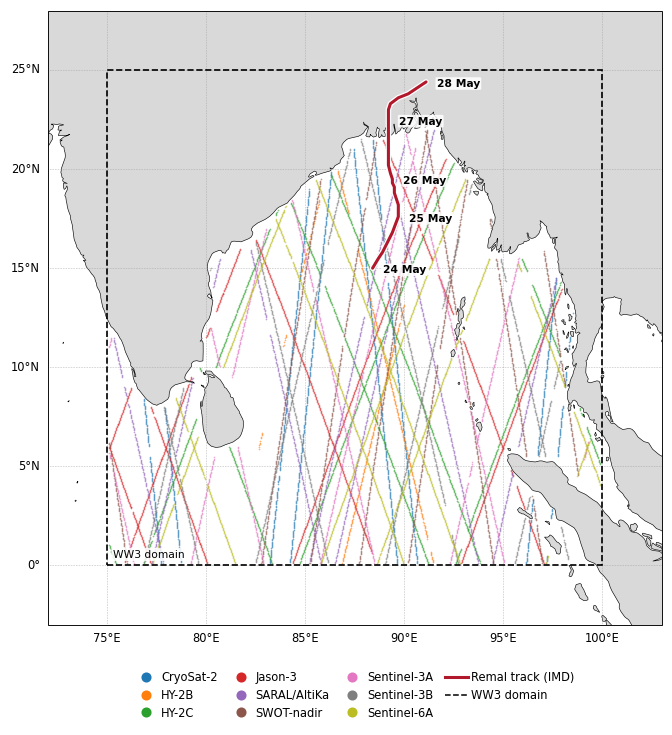

In [7]:
# ======================================================================
# CELL 7 - FIGURE 1 (study area)
# Drawing only: nothing in this cell changes any number in the paper.
# All the options are in CELL 1 - SETTINGS (search for FIG1_).
# ======================================================================

# ----------------------------------------------------------------------
# 0. Is cartopy installed? (cartopy draws the real coastlines.)
# ----------------------------------------------------------------------
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAVE_CARTOPY = True
except ImportError:
    HAVE_CARTOPY = False
    print('NOTE: cartopy is not installed, so Figure 1 is drawn WITHOUT the zoom-out.')
    print('      Install it with  conda install -c conda-forge cartopy  (or  pip install cartopy),')
    print('      then restart the notebook and run it again.')

# ----------------------------------------------------------------------
# 1. WW3 domain edges (taken from the model grid itself) and map edges.
# ----------------------------------------------------------------------
domain_west, domain_east = float(lon.min()), float(lon.max())
domain_south, domain_north = float(lat.min()), float(lat.max())

pad = FIG1_MAP_PADDING_DEG if HAVE_CARTOPY else 0.5
map_west, map_east = domain_west - pad, domain_east + pad
map_south, map_north = domain_south - pad, domain_north + pad

# ----------------------------------------------------------------------
# 2. Empty map + land.
# ----------------------------------------------------------------------
if HAVE_CARTOPY:
    data_crs = ccrs.PlateCarree()   # our data are plain longitude / latitude
    fig, ax = plt.subplots(figsize=FIG1_FIGSIZE, constrained_layout=True,
                           subplot_kw={'projection': ccrs.PlateCarree()})
    ax.set_extent([map_west, map_east, map_south, map_north], crs=data_crs)
    ax.set_facecolor(FIG1_OCEAN_COLOUR)
    ax.add_feature(cfeature.LAND.with_scale(FIG1_COASTLINE_DETAIL),
                   facecolor=FIG1_LAND_COLOUR, edgecolor='none', zorder=1)
    ax.add_feature(cfeature.COASTLINE.with_scale(FIG1_COASTLINE_DETAIL),
                   edgecolor='k', linewidth=0.4, zorder=2)
    plot_kw = {'transform': data_crs}   # tells cartopy the points are lon/lat
else:
    fig, ax = plt.subplots(figsize=FIG1_FIGSIZE, constrained_layout=True)
    ax.contourf(lon, lat, land.astype(float), levels=[0.5, 1.5], colors=[FIG1_LAND_COLOUR], zorder=1)
    ax.contour(lon, lat, land.astype(float), levels=[0.5], colors='k', linewidths=0.4, zorder=2)
    plot_kw = {}

# ----------------------------------------------------------------------
# 3. Altimeter points, one colour per satellite mission.
# ----------------------------------------------------------------------
missions = sorted(df_common['satellite'].astype(str).unique())
mission_cmap = plt.get_cmap('tab10')     # <---------------- change this to customise the mission colours
legend_handles = []

for i, mission in enumerate(missions):
    mission_data = df_common[df_common['satellite'].astype(str) == mission]
    colour = mission_cmap(i % 10)
    ax.scatter(
        mission_data['longitude'], mission_data['latitude'],
        s=FIG1_ALTIMETER_POINT_SIZE, color=colour, alpha=0.6, linewidths=0,
        zorder=3, rasterized=True, **plot_kw
    )
    legend_handles.append(
        Line2D([], [], marker='o', linestyle='', color=colour, markersize=4, label=mission)
    )

# ----------------------------------------------------------------------
# 4. Cyclone track: ONE plain line.
#    A slightly wider white line underneath keeps it visible over the dots.
# ----------------------------------------------------------------------
ax.plot(track['longitude'], track['latitude'], color='white',
        linewidth=FIG1_TRACK_WIDTH + 1.6, solid_capstyle='round', zorder=5, **plot_kw)
ax.plot(track['longitude'], track['latitude'], color=FIG1_TRACK_COLOUR,
        linewidth=FIG1_TRACK_WIDTH, solid_capstyle='round', zorder=6, **plot_kw)

# Optional: label one position per day ('24 May', '25 May', ...). Text only, no markers.
if FIG1_LABEL_DAYS:
    for day in pd.date_range(T0.normalize(), T1.normalize(), freq='D'):
        one_day = track[track['time'] == day]
        if len(one_day) > 0:
            ax.annotate(
                f'{day:%d May}',
                (one_day['longitude'].iloc[0], one_day['latitude'].iloc[0]),
                xytext=(7, -3), textcoords='offset points',      # <---------------- change this to move the day labels
                fontsize=7, fontweight='bold', zorder=8,
                bbox=dict(boxstyle='round,pad=0.12', fc='white', ec='none', alpha=0.85)
            )

# ----------------------------------------------------------------------
# 5. Dashed WW3 domain box + a small label in its corner.
# ----------------------------------------------------------------------
ax.add_patch(plt.Rectangle(
    (domain_west, domain_south),
    domain_east - domain_west, domain_north - domain_south,
    fill=False, edgecolor='k', linewidth=1.1, linestyle='--', zorder=9, **plot_kw
))
ax.text(domain_west + 0.3, domain_south + 0.3, 'WW3 domain',
        fontsize=7, ha='left', va='bottom', zorder=9,
        bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85), **plot_kw)

# ----------------------------------------------------------------------
# 6. Longitude / latitude labels, grid and legend.
# ----------------------------------------------------------------------
GRID_STEP_DEG = 5                        # <---------------- change this to customise the spacing of the lat/lon grid lines
lon_ticks = np.arange(np.ceil(map_west / GRID_STEP_DEG) * GRID_STEP_DEG, map_east + 0.01, GRID_STEP_DEG)
lat_ticks = np.arange(np.ceil(map_south / GRID_STEP_DEG) * GRID_STEP_DEG, map_north + 0.01, GRID_STEP_DEG)

if HAVE_CARTOPY:
    grid = ax.gridlines(crs=data_crs, draw_labels=True, xlocs=lon_ticks, ylocs=lat_ticks,
                        linestyle=':', linewidth=0.4, color='0.6', zorder=0)
    grid.top_labels = False
    grid.right_labels = False
    grid.xlabel_style = {'size': 7.5}
    grid.ylabel_style = {'size': 7.5}
else:
    ax.set_xlim(map_west, map_east)
    ax.set_ylim(map_south, map_north)
    ax.set_aspect('equal')
    ax.set_xticks(lon_ticks)
    ax.set_yticks(lat_ticks)
    ax.xaxis.set_major_formatter(lambda x, p: f'{x:g}°E')
    ax.yaxis.set_major_formatter(lambda y, p: (f'{y:g}°N' if y > 0 else (f'{-y:g}°S' if y < 0 else '0°')))
    ax.grid(True, linestyle=':', linewidth=0.4, color='0.6', zorder=0)
    for spine in ax.spines.values():
        spine.set_visible(True)

legend_handles.append(
    Line2D([], [], color=FIG1_TRACK_COLOUR, linewidth=FIG1_TRACK_WIDTH, label='Remal track (IMD)')
)
legend_handles.append(Line2D([], [], color='k', linestyle='--', linewidth=1, label='WW3 domain'))

ax.legend(
    handles=legend_handles,
    loc='upper center', bbox_to_anchor=(0.5, -0.06),   # <---------------- change this to move the legend
    ncol=FIG1_LEGEND_COLUMNS, frameon=False, markerscale=1.4,
    columnspacing=1.0, handletextpad=0.3
)

FIG1_PATH = save_figure(fig, 'Figure_1_study_area')
plt.show()



## Figure 2 and Table 2 - Validation against satellite Hs

All three products are evaluated on the **same 15,635-point common sample** when the corrected input files are used.

Figure 2 uses 0.1 m x 0.1 m cells. Colour represents the **percentage of the entire common sample** in each cell, so all three panels share one colour scale.


Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/tables/Table_2_validation_statistics.csv


,Product,N,Bias (m),MAE (m),RMSE (m),r
0,ERA5,15635,-0.189,0.260,0.341,0.935
1,WW3 CONTROL,15635,-0.032,0.216,0.286,0.945
2,WW3 OSCAR,15635,-0.073,0.211,0.268,0.954


Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/figures/Figure_2_Hs_validation.png


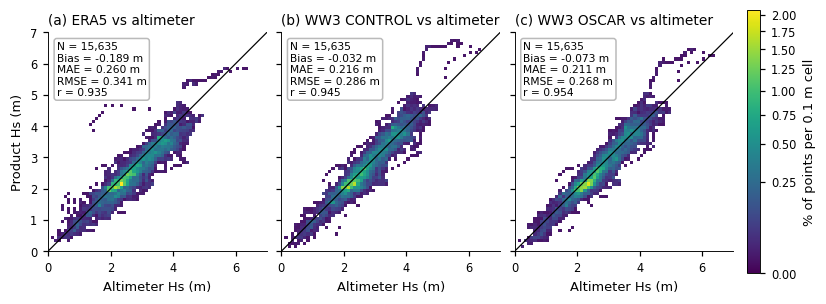

In [8]:

# ======================================================================
# CELL 8 - TABLE 2 + FIGURE 2
# ======================================================================

products = [
    ('ERA5', 'era5_swh_m'),
    ('WW3 CONTROL', 'hs_control_m'),
    ('WW3 OSCAR', 'hs_oscar_m')
]

# ------------------------------
# Table 2
# ------------------------------
metric_rows = []

for product_name, column_name in products:
    result = calculate_metrics(df_common['hs_obs_m'], df_common[column_name])
    metric_rows.append({
        'Product': product_name,
        'N': result['N'],
        'Bias (m)': result['Bias'],
        'MAE (m)': result['MAE'],
        'RMSE (m)': result['RMSE'],
        'r': result['r']
    })

table2 = pd.DataFrame(metric_rows)
save_table(table2, 'Table_2_validation_statistics.csv')
display(table2.round({'Bias (m)': 3, 'MAE (m)': 3, 'RMSE (m)': 3, 'r': 3}))

# ------------------------------
# Figure 2
# ------------------------------
max_hs = max(
    df_common['hs_obs_m'].max(),
    df_common['era5_swh_m'].max(),
    df_common['hs_control_m'].max(),
    df_common['hs_oscar_m'].max()
)
plot_limit = float(np.ceil(max_hs))

bins = np.arange(0, plot_limit + 0.1, 0.1)
weights = np.full(len(df_common), 100.0 / len(df_common))

# Find one common maximum for the colour scale.
colour_max = 0
for product_name, column_name in products:
    histogram, _, _ = np.histogram2d(
        df_common['hs_obs_m'], df_common[column_name],
        bins=[bins, bins], weights=weights
    )
    colour_max = max(colour_max, histogram.max())

fig, axes = plt.subplots(
    1, 3, figsize=(7.4, 2.9),
    sharex=True, sharey=True,
    constrained_layout=True
)

panel_letters = ['a', 'b', 'c']

for i in range(3):
    ax = axes[i]
    product_name, column_name = products[i]
    row = table2.iloc[i]

    hist = ax.hist2d(
        df_common['hs_obs_m'], df_common[column_name],
        bins=[bins, bins], weights=weights,
        cmap='viridis',
        norm=PowerNorm(0.5, vmin=0, vmax=colour_max),
        cmin=1e-9, rasterized=True
    )

    ax.plot([0, plot_limit], [0, plot_limit], color='k', linewidth=0.8)
    ax.set_xlim(0, plot_limit)
    ax.set_ylim(0, plot_limit)
    ax.set_aspect('equal')
    ax.set_title(f'({panel_letters[i]}) {product_name} vs altimeter', loc='left')
    ax.set_xlabel('Altimeter Hs (m)')

    text = (
        f'N = {int(row["N"]):,}\n'
        f'Bias = {row["Bias (m)"]:+.3f} m\n'
        f'MAE = {row["MAE (m)"]:.3f} m\n'
        f'RMSE = {row["RMSE (m)"]:.3f} m\n'
        f'r = {row["r"]:.3f}'
    )
    ax.text(
        0.04, 0.96, text,
        transform=ax.transAxes, va='top', ha='left', fontsize=7,
        bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='0.7', alpha=0.9)
    )

axes[0].set_ylabel('Product Hs (m)')
fig.colorbar(
    hist[3], ax=axes, location='right', shrink=0.85, pad=0.02,
    label='% of points per 0.1 m cell'
)

FIG2_PATH = save_figure(fig, 'Figure_2_Hs_validation')
plt.show()



## Figure 3 - Direct response of WW3 to prescribed OSCAR currents

This figure compares the two WW3 simulations directly.

- Panel (a) is the time mean of `OSCAR - CONTROL` at every grid cell.
- Panel (b) first takes `abs(OSCAR - CONTROL)` and then calculates a latitude-weighted domain mean for every hour.
- The latitude weighting is `cos(latitude)` because grid-cell area decreases toward the poles.

This is a **net current-forcing response**, not a pure refraction-only effect, because RWND was active.


/tmp/ipykernel_28141/2521785567.py:23: RuntimeWarning: Mean of empty slice
  mean_delta_map = np.nanmean(delta_hs, axis=0)


Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/figures/Figure_3_WW3_current_response.png


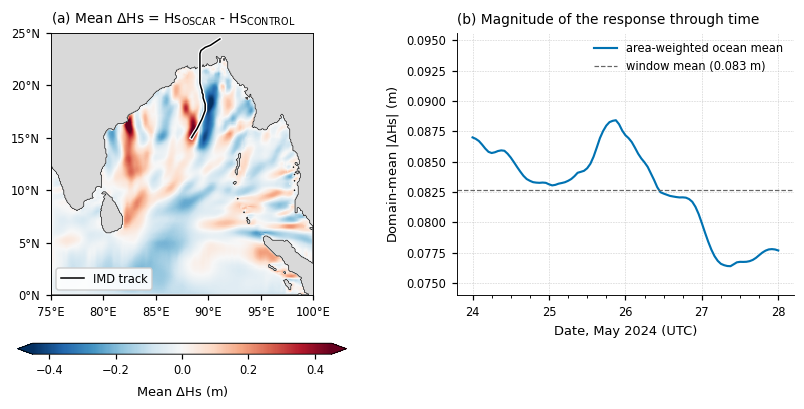

In [9]:

# ======================================================================
# CELL 9 - FIGURE 3 (direct WW3 response to the OSCAR currents)
# Panel (a): time-mean map.  Panel (b): hourly domain-mean |Delta Hs|.
# The calculations at the top are used in the paper text; the plotting
# below only changes how the figure looks.
# ======================================================================

# Difference between the two WW3 experiments.
delta_hs = hs_oscar - hs_control
valid = np.isfinite(delta_hs)

# Approximate area weighting for a regular latitude/longitude grid.
latitude_weights_2d = np.cos(np.deg2rad(lat))[:, None] * np.ones((len(lat), len(lon)))
latitude_weights_3d = np.broadcast_to(latitude_weights_2d, delta_hs.shape)
weights = np.where(valid, latitude_weights_3d, 0.0)

# Hourly domain-mean magnitude of the response.
weighted_abs_sum = (np.where(valid, np.abs(delta_hs), 0.0) * weights).sum(axis=(1, 2))
weight_sum = weights.sum(axis=(1, 2))
domain_mean_abs = weighted_abs_sum / weight_sum

# Time-mean map.
mean_delta_map = np.nanmean(delta_hs, axis=0)
mean_delta_map = np.ma.masked_where(land | ~np.isfinite(mean_delta_map), mean_delta_map)

# Save the exact time series plotted in panel (b).
figure3_data = pd.DataFrame({
    'time_utc': times,
    'domain_mean_abs_delta_hs_m': domain_mean_abs
})
figure3_data_path = os.path.join(DATA_DIR, 'Figure_3_time_series.csv')
figure3_data.to_csv(figure3_data_path, index=False)
FILES_CREATED.append(figure3_data_path)

# Symmetric map limits based on the 99.5th percentile of the time-mean response.
map_values = np.abs(mean_delta_map.filled(np.nan))
colour_limit = max(0.05, np.ceil(np.nanpercentile(map_values, 99.5) * 20) / 20)

fig = plt.figure(figsize=(7.4, 3.6), constrained_layout=True)   # <---------------- change this to customise Figure 3 size
grid = fig.add_gridspec(1, 2, width_ratios=[1.15, 1])
ax_map = fig.add_subplot(grid[0])
ax_time = fig.add_subplot(grid[1])

# ------------------------------
# Panel (a): map
# ------------------------------
mesh = ax_map.pcolormesh(
    lon, lat, mean_delta_map,
    cmap=FIG3_COLORMAP, vmin=-colour_limit, vmax=colour_limit,   # colour map is set in CELL 1
    shading='auto', rasterized=True
)
ax_map.contourf(lon, lat, land.astype(float), levels=[0.5, 1.5], colors=['#d9d9d9'])
ax_map.contour(lon, lat, land.astype(float), levels=[0.5], colors='k', linewidths=0.4)

# White underlay makes the black cyclone track visible over both red and blue areas.
ax_map.plot(track['longitude'], track['latitude'], color='white', linewidth=2.6)
ax_map.plot(track['longitude'], track['latitude'], color='k', linewidth=1.0, label='IMD track')

ax_map.set_aspect('equal')
ax_map.set_xlim(lon.min(), lon.max())
ax_map.set_ylim(lat.min(), lat.max())
ax_map.xaxis.set_major_formatter(lambda x, p: f'{x:g}°E')
ax_map.yaxis.set_major_formatter(lambda y, p: f'{y:g}°N')
ax_map.set_title(r'(a) Mean $\Delta$Hs = Hs$_{OSCAR}$ - Hs$_{CONTROL}$', loc='left')
ax_map.legend(loc='lower left', frameon=True, framealpha=0.9)
for spine in ax_map.spines.values():
    spine.set_visible(True)

# Colour bar for panel (a). Its position is set in CELL 1 (FIG3_COLORBAR_LOCATION).
if FIG3_COLORBAR_LOCATION == 'bottom':
    colour_bar = fig.colorbar(mesh, ax=ax_map, location='bottom', shrink=0.85,   # <---------------- shrink changes the bar length
                              pad=0.02, aspect=30, extend='both')
else:
    colour_bar = fig.colorbar(mesh, ax=ax_map, location='right', shrink=0.8,
                              pad=0.02, extend='both')
colour_bar.set_label(r'Mean $\Delta$Hs (m)')
# Keep only a few tick labels so they do not overlap.
from matplotlib.ticker import MaxNLocator
FIG3_COLORBAR_N_TICKS = 5     # <---------------- change this to show more / fewer numbers on the colour bar
colour_bar.locator = MaxNLocator(nbins=FIG3_COLORBAR_N_TICKS, symmetric=True)
colour_bar.update_ticks()

# ------------------------------
# Panel (b): time series
# ------------------------------
ax_time.plot(times, domain_mean_abs, color=C_FOLLOWING, linewidth=1.4, label='area-weighted ocean mean')
ax_time.axhline(
    domain_mean_abs.mean(), color='0.4', linestyle='--', linewidth=0.8,
    label=f'window mean ({domain_mean_abs.mean():.3f} m)'
)
ax_time.set_title('(b) Magnitude of the response through time', loc='left')
ax_time.set_ylabel(r'Domain-mean |$\Delta$Hs| (m)')
ax_time.set_xlabel('Date, May 2024 (UTC)')
ax_time.xaxis.set_major_locator(mdates.DayLocator())
ax_time.xaxis.set_major_formatter(mdates.DateFormatter('%d'))
ax_time.xaxis.set_minor_locator(mdates.HourLocator(byhour=[6, 12, 18]))

# Keep the original non-zero-start y-axis.
y_span = max(domain_mean_abs.max() - domain_mean_abs.min(), 0.05 * domain_mean_abs.mean())
ax_time.set_ylim(domain_mean_abs.min() - 0.2 * y_span, domain_mean_abs.max() + 0.6 * y_span)
ax_time.grid(True, linestyle=':', linewidth=0.4)
ax_time.legend(loc='upper right', frameon=False)

FIG3_PATH = save_figure(fig, 'Figure_3_WW3_current_response')
plt.show()



## Figure 4 - Does the response depend on current direction?

This is the most technical figure, so the calculation is separated into small steps.

### Panel (a)
For each threshold `U_t`, make cumulative groups of:

- opposing currents: `U_parallel < -U_t`
- following currents: `U_parallel > U_t`
- all strong currents: `current_speed > U_t`

Then plot `<Hobs>/<HERA5>`.

### Panel (b)
Split `U_parallel` into 0.1 m/s bins and plot the median and interquartile range of `Delta Hs = OSCAR - CONTROL`.

### Panel (c)
For the same cumulative threshold groups, calculate:

`RMSE(OSCAR) - RMSE(CONTROL)`

Negative values mean the OSCAR run is closer to the altimeter.

The confidence bands are generated by resampling **passes** 5,000 times. The plotting section is kept separate from the calculations so its layout can be changed later without changing any result.

**Layout:** the three panels are drawn side by side in one row. Size, font size and line width are set in CELL 1 (`FIG4_...`).


Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/figures/Figure_4_current_dependence.png


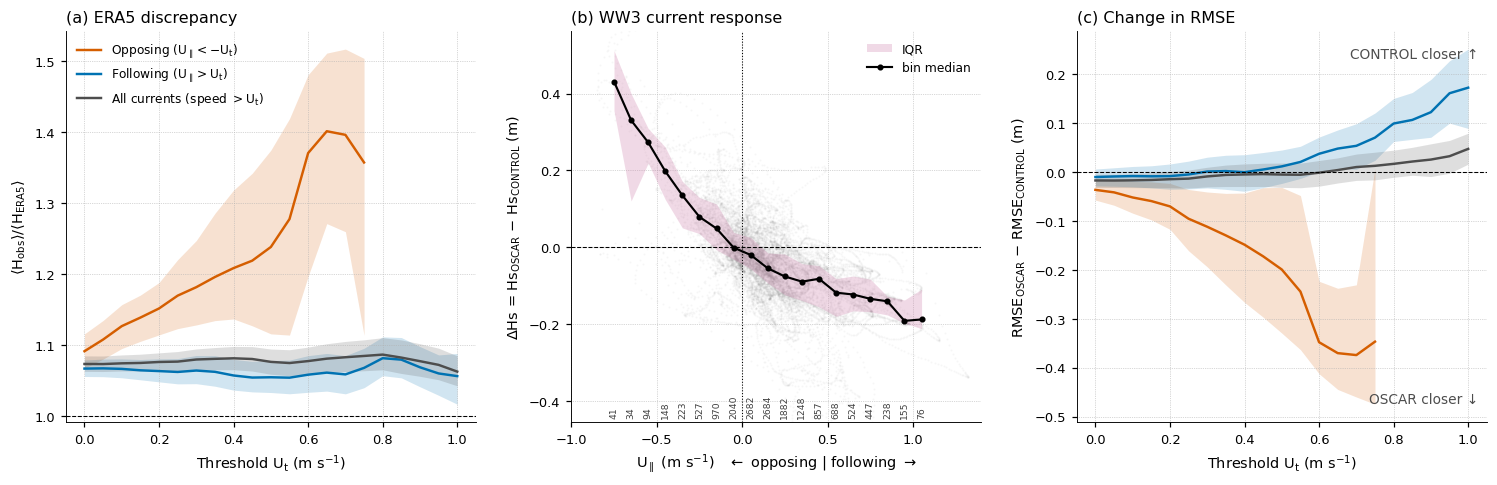

In [10]:

# ======================================================================
# CELL 10 - FIGURE 4 CALCULATIONS + PLOT (three panels side by side)
# PART 1-2 = calculations (these give the numbers in the paper - do not edit)
# PLOTTING  = drawing only (safe to edit)
# ======================================================================

# Shorter names make the formulas below easier to read.
obs = df_common['hs_obs_m'].to_numpy(float)
era5 = df_common['era5_swh_m'].to_numpy(float)
control = df_common['hs_control_m'].to_numpy(float)
oscar = df_common['hs_oscar_m'].to_numpy(float)
u_parallel = df_common['u_parallel_control_ms'].to_numpy(float)
current_speed = df_common['current_speed_ms'].to_numpy(float)

# Convert pass names into integer codes: 0, 1, 2, ...
pass_codes, pass_names = pd.factorize(df_common['altimeter_pass_id'], sort=False)
number_of_passes = len(pass_names)

# Generate ONE fixed set of pass-bootstrap samples for all threshold curves.
rng = np.random.default_rng(FIG4_BOOTSTRAP_SEED)
bootstrap_pass_indices = rng.integers(
    0, number_of_passes,
    size=(N_BOOT, number_of_passes)
)


def calculate_threshold_point(mask):
    """Calculate one Figure 4(a/c) point and its pass-bootstrap confidence intervals."""

    # --------------------------------------------------------------
    # A. Point estimate from every selected 1-Hz observation.
    # --------------------------------------------------------------
    selected_obs = obs[mask]
    selected_era5 = era5[mask]
    selected_control = control[mask]
    selected_oscar = oscar[mask]

    n = len(selected_obs)
    passes = np.unique(pass_codes[mask]).size

    # Some extreme thresholds can contain zero points. Keep the row in the
    # saved CSV, but return NaN statistics so it is not plotted.
    if n == 0:
        return {
            'N': 0, 'passes': 0,
            'ratio_era5': np.nan, 'ratio_control': np.nan, 'ratio_oscar': np.nan,
            'ratio_era5_low': np.nan, 'ratio_era5_high': np.nan,
            'ratio_control_low': np.nan, 'ratio_control_high': np.nan,
            'ratio_oscar_low': np.nan, 'ratio_oscar_high': np.nan,
            'rmsd_change': np.nan, 'rmsd_change_low': np.nan, 'rmsd_change_high': np.nan
        }

    ratio_era5 = selected_obs.mean() / selected_era5.mean()
    ratio_control = selected_obs.mean() / selected_control.mean()
    ratio_oscar = selected_obs.mean() / selected_oscar.mean()

    rmsd_control = np.sqrt(np.mean((selected_control - selected_obs) ** 2))
    rmsd_oscar = np.sqrt(np.mean((selected_oscar - selected_obs) ** 2))
    rmsd_change = rmsd_oscar - rmsd_control

    # --------------------------------------------------------------
    # B. Put the necessary sums into one row per pass.
    # This lets the bootstrap resample WHOLE PASSES.
    # --------------------------------------------------------------
    count_by_pass = np.bincount(pass_codes[mask], minlength=number_of_passes).astype(float)
    obs_sum_by_pass = np.bincount(pass_codes[mask], weights=selected_obs, minlength=number_of_passes)
    era5_sum_by_pass = np.bincount(pass_codes[mask], weights=selected_era5, minlength=number_of_passes)
    control_sum_by_pass = np.bincount(pass_codes[mask], weights=selected_control, minlength=number_of_passes)
    oscar_sum_by_pass = np.bincount(pass_codes[mask], weights=selected_oscar, minlength=number_of_passes)
    control_sq_error_by_pass = np.bincount(
        pass_codes[mask], weights=(selected_control - selected_obs) ** 2,
        minlength=number_of_passes
    )
    oscar_sq_error_by_pass = np.bincount(
        pass_codes[mask], weights=(selected_oscar - selected_obs) ** 2,
        minlength=number_of_passes
    )

    # --------------------------------------------------------------
    # C. Bootstrap the passes.
    # --------------------------------------------------------------
    boot_n = count_by_pass[bootstrap_pass_indices].sum(axis=1)
    boot_obs = obs_sum_by_pass[bootstrap_pass_indices].sum(axis=1)
    boot_era5 = era5_sum_by_pass[bootstrap_pass_indices].sum(axis=1)
    boot_control = control_sum_by_pass[bootstrap_pass_indices].sum(axis=1)
    boot_oscar = oscar_sum_by_pass[bootstrap_pass_indices].sum(axis=1)
    boot_control_sse = control_sq_error_by_pass[bootstrap_pass_indices].sum(axis=1)
    boot_oscar_sse = oscar_sq_error_by_pass[bootstrap_pass_indices].sum(axis=1)

    good_boot = boot_n > 0
    boot_n = boot_n[good_boot]

    boot_ratio_era5 = boot_obs[good_boot] / boot_era5[good_boot]
    boot_ratio_control = boot_obs[good_boot] / boot_control[good_boot]
    boot_ratio_oscar = boot_obs[good_boot] / boot_oscar[good_boot]
    boot_rmsd_change = (
        np.sqrt(boot_oscar_sse[good_boot] / boot_n)
        - np.sqrt(boot_control_sse[good_boot] / boot_n)
    )

    return {
        'N': n,
        'passes': passes,
        'ratio_era5': ratio_era5,
        'ratio_control': ratio_control,
        'ratio_oscar': ratio_oscar,
        'ratio_era5_low': np.percentile(boot_ratio_era5, 2.5),
        'ratio_era5_high': np.percentile(boot_ratio_era5, 97.5),
        'ratio_control_low': np.percentile(boot_ratio_control, 2.5),
        'ratio_control_high': np.percentile(boot_ratio_control, 97.5),
        'ratio_oscar_low': np.percentile(boot_ratio_oscar, 2.5),
        'ratio_oscar_high': np.percentile(boot_ratio_oscar, 97.5),
        'rmsd_change': rmsd_change,
        'rmsd_change_low': np.percentile(boot_rmsd_change, 2.5),
        'rmsd_change_high': np.percentile(boot_rmsd_change, 97.5),
    }


# ----------------------------------------------------------------------
# PART 1 - CUMULATIVE THRESHOLD CURVES FOR PANELS (a) AND (c)
# ----------------------------------------------------------------------
threshold_rows = []

for regime in ['opposing', 'following', 'total']:
    for threshold in THRESHOLDS:

        if regime == 'opposing':
            mask = u_parallel < -threshold
        elif regime == 'following':
            mask = u_parallel > threshold
        else:
            if threshold == 0:
                mask = np.ones(len(df_common), dtype=bool)
            else:
                mask = current_speed > threshold

        result = calculate_threshold_point(mask)
        result['regime'] = regime
        result['threshold_ms'] = threshold

        # A point is plotted only when it meets the frozen reporting rule.
        result['shown'] = (
            result['N'] >= MIN_N_CURVE
            and result['passes'] >= MIN_PASSES_CURVE
        )
        threshold_rows.append(result)

threshold_data = pd.DataFrame(threshold_rows)
threshold_path = os.path.join(DATA_DIR, 'Figure_4_threshold_curves.csv')
threshold_data.to_csv(threshold_path, index=False)
FILES_CREATED.append(threshold_path)

# ----------------------------------------------------------------------
# PART 2 - 0.1 m/s U_parallel BINS FOR PANEL (b)
# ----------------------------------------------------------------------
bin_rows = []

for lower, upper in zip(BIN_EDGES[:-1], BIN_EDGES[1:]):
    mask = (u_parallel > lower) & (u_parallel <= upper)
    one_bin = df_common.loc[mask]

    if len(one_bin) == 0:
        continue

    bin_rows.append({
        'bin_low_ms': lower,
        'bin_high_ms': upper,
        'bin_centre_ms': (lower + upper) / 2,
        'N': len(one_bin),
        'passes': one_bin['altimeter_pass_id'].nunique(),
        'median_dhs_m': one_bin['dhs'].median(),
        'q25_dhs_m': one_bin['dhs'].quantile(0.25),
        'q75_dhs_m': one_bin['dhs'].quantile(0.75),
        'shown': len(one_bin) >= MIN_N_BIN
    })

bin_data = pd.DataFrame(bin_rows)
bin_path = os.path.join(DATA_DIR, 'Figure_4_binned_response.csv')
bin_data.to_csv(bin_path, index=False)
FILES_CREATED.append(bin_path)

# ======================================================================
# PLOTTING ONLY - changing this block does NOT change any number.
# Layout: (a) | (b) | (c) side by side in one row.
# Options live in CELL 1: FIG4_FIGSIZE, FIG4_FONT_SIZE, FIG4_LINE_WIDTH,
# FIG4_SHOW_RAW_POINTS, FIG4_SHOW_BIN_COUNTS and the C_... colours.
# ======================================================================

# Temporarily use a bigger font for this figure only.
fig4_style = {
    'font.size': FIG4_FONT_SIZE,
    'axes.titlesize': FIG4_FONT_SIZE + 1.5,
    'axes.labelsize': FIG4_FONT_SIZE + 0.5,
    'xtick.labelsize': FIG4_FONT_SIZE - 0.5,
    'ytick.labelsize': FIG4_FONT_SIZE - 0.5,
    'legend.fontsize': FIG4_FONT_SIZE - 1,
}

with plt.rc_context(fig4_style):

    fig, axes = plt.subplots(1, 3, figsize=FIG4_FIGSIZE, constrained_layout=True)
    fig.get_layout_engine().set(wspace=FIG4_PANEL_GAP)   # space between panels (set in CELL 1)
    ax_a, ax_b, ax_c = axes

    # Colour + legend text for each regime.
    regime_style = {
        'opposing':  (C_OPPOSING,  r'Opposing ($U_\parallel < -U_t$)'),
        'following': (C_FOLLOWING, r'Following ($U_\parallel > U_t$)'),
        'total':     (C_TOTAL,     r'All currents (speed $> U_t$)')
    }

    # ------------------------------------------------------------------
    # Panel (a): ratio of mean observed Hs to mean ERA5 Hs
    # line = value, shaded band = 95% pass-bootstrap interval
    # ------------------------------------------------------------------
    for regime in ['opposing', 'following', 'total']:
        colour, label = regime_style[regime]
        subset = threshold_data[(threshold_data['regime'] == regime) & threshold_data['shown']]
        ax_a.plot(subset['threshold_ms'], subset['ratio_era5'],
                  color=colour, linewidth=FIG4_LINE_WIDTH, label=label)
        ax_a.fill_between(subset['threshold_ms'], subset['ratio_era5_low'], subset['ratio_era5_high'],
                          color=colour, alpha=0.18, linewidth=0)

    ax_a.axhline(1, color='k', linewidth=0.7, linestyle='--')
    ax_a.set_xlim(-0.05, 1.05)
    ax_a.set_xlabel(r'Threshold $U_t$ (m s$^{-1}$)')
    ax_a.set_ylabel(r'$\langle H_{obs}\rangle / \langle H_{ERA5}\rangle$')
    ax_a.set_title('(a) ERA5 discrepancy', loc='left')
    ax_a.legend(loc='upper left', frameon=False)            # <---------------- change this to move the legend
    ax_a.grid(True, linestyle=':', linewidth=0.45)

    # ------------------------------------------------------------------
    # Panel (b): OSCAR - CONTROL wave height in U_parallel bins
    # grey dots = every 1-Hz point, pink band = IQR, black line = bin median
    # ------------------------------------------------------------------
    if FIG4_SHOW_RAW_POINTS:
        ax_b.scatter(u_parallel, df_common['dhs'], s=1.5, color='0.55', alpha=0.07,
                     linewidths=0, rasterized=True, zorder=1)

    shown_bins = bin_data[bin_data['shown']]

    ax_b.fill_between(shown_bins['bin_centre_ms'], shown_bins['q25_dhs_m'], shown_bins['q75_dhs_m'],
                      color=C_IQR, alpha=0.28, linewidth=0, label='IQR', zorder=2)
    ax_b.plot(shown_bins['bin_centre_ms'], shown_bins['median_dhs_m'],
              color='k', linewidth=1.4, marker='o', markersize=3.0, label='bin median', zorder=3)

    ax_b.axhline(0, color='k', linewidth=0.7, linestyle='--')
    ax_b.axvline(0, color='k', linewidth=0.7, linestyle=':')

    # y-range: ignore the most extreme 0.5% of points so the plot is readable.
    y_low, y_high = np.nanpercentile(df_common['dhs'], [0.5, 99.5])
    ax_b.set_ylim(min(y_low, shown_bins['q25_dhs_m'].min()) - 0.05,
                  max(y_high, shown_bins['q75_dhs_m'].max()) + 0.05)

    # Small numbers along the bottom = how many points are in each bin.
    if FIG4_SHOW_BIN_COUNTS:
        for row in shown_bins.itertuples():
            ax_b.text(row.bin_centre_ms, 0.01, f'{row.N}',
                      transform=ax_b.get_xaxis_transform(), rotation=90,
                      ha='center', va='bottom', fontsize=FIG4_FONT_SIZE - 3, color='0.25')

    ax_b.set_xlim(BIN_EDGES[0], BIN_EDGES[-1])
    ax_b.set_xlabel(r'$U_\parallel$ (m s$^{-1}$)   $\leftarrow$ opposing | following $\rightarrow$')
    ax_b.set_ylabel(r'$\Delta$Hs = Hs$_{OSCAR}$ $-$ Hs$_{CONTROL}$ (m)')
    ax_b.set_title('(b) WW3 current response', loc='left')
    ax_b.legend(loc='upper right', frameon=False)            # <---------------- change this to move the legend
    ax_b.grid(True, linestyle=':', linewidth=0.45)

    # ------------------------------------------------------------------
    # Panel (c): change in RMSE between the two WW3 runs
    # below zero = OSCAR closer to the altimeters
    # (colours match panel (a), so no separate legend is needed)
    # ------------------------------------------------------------------
    for regime in ['opposing', 'following', 'total']:
        colour, label = regime_style[regime]
        subset = threshold_data[(threshold_data['regime'] == regime) & threshold_data['shown']]
        ax_c.plot(subset['threshold_ms'], subset['rmsd_change'],
                  color=colour, linewidth=FIG4_LINE_WIDTH)
        ax_c.fill_between(subset['threshold_ms'], subset['rmsd_change_low'], subset['rmsd_change_high'],
                          color=colour, alpha=0.18, linewidth=0)

    ax_c.axhline(0, color='k', linewidth=0.7, linestyle='--')
    ax_c.set_xlim(-0.05, 1.05)
    ax_c.set_xlabel(r'Threshold $U_t$ (m s$^{-1}$)')
    ax_c.set_ylabel(r'RMSE$_{OSCAR}$ $-$ RMSE$_{CONTROL}$ (m)')
    ax_c.set_title('(c) Change in RMSE', loc='left')
    ax_c.text(0.98, 0.04, 'OSCAR closer ↓', transform=ax_c.transAxes,
              ha='right', va='bottom', color='0.3')
    ax_c.text(0.98, 0.96, 'CONTROL closer ↑', transform=ax_c.transAxes,
              ha='right', va='top', color='0.3')
    ax_c.grid(True, linestyle=':', linewidth=0.45)

    FIG4_PATH = save_figure(fig, 'Figure_4_current_dependence')
    plt.show()



## Table 4 - Pass-level robustness

The 1-Hz observations within one satellite pass are not fully independent. Table 4 therefore gives **each pass one vote**:

1. Calculate CONTROL and OSCAR MAE separately for each pass.
2. Keep passes with at least 10 points.
3. Compute `Delta MAE_pass = MAE_OSCAR - MAE_CONTROL`.
4. Bootstrap the pass-level values with seed 43.
5. Also report a two-sided sign test.

Negative `Delta MAE_pass` means OSCAR is closer for that pass.


In [11]:

# ======================================================================
# CELL 11 - TABLE 4 (pass-level robustness; Table 4 in the paper)
# ======================================================================

# Build one row per altimeter pass.
pass_rows = []

for pass_id, one_pass in df_common.groupby('altimeter_pass_id'):
    n = len(one_pass)

    # Table 4 uses only passes with at least MIN_POINTS_PER_PASS points.
    if n < MIN_POINTS_PER_PASS:
        continue

    mae_control = one_pass['abs_error_control'].mean()
    mae_oscar = one_pass['abs_error_oscar'].mean()

    pass_rows.append({
        'pass_id': pass_id,
        'mission': one_pass['satellite'].iloc[0],
        'N': n,
        'mae_control': mae_control,
        'mae_oscar': mae_oscar,
        'delta_mae': mae_oscar - mae_control
    })

pass_table = pd.DataFrame(pass_rows)
delta = pass_table['delta_mae'].to_numpy(float)

# Bootstrap WHOLE PASS-LEVEL delta-MAE values.
rng = np.random.default_rng(TABLE3_BOOTSTRAP_SEED)
bootstrap_indices = rng.integers(0, len(delta), size=(N_BOOT, len(delta)))
bootstrap_samples = delta[bootstrap_indices]

bootstrap_means = bootstrap_samples.mean(axis=1)
bootstrap_medians = np.median(bootstrap_samples, axis=1)

mean_delta = delta.mean()
median_delta = np.median(delta)
mean_ci = np.percentile(bootstrap_means, [2.5, 97.5])
median_ci = np.percentile(bootstrap_medians, [2.5, 97.5])

oscar_better = int((delta < 0).sum())
nonzero = int((delta != 0).sum())
sign_test_p = stats.binomtest(oscar_better, nonzero, 0.5).pvalue if nonzero > 0 else np.nan

table3 = pd.DataFrame([
    ('Passes in common sample', df_common['altimeter_pass_id'].nunique()),
    (f'Valid passes (at least {MIN_POINTS_PER_PASS} points)', len(pass_table)),
    ('Mean pass MAE, CONTROL (m)', f'{pass_table["mae_control"].mean():.3f}'),
    ('Mean pass MAE, OSCAR (m)', f'{pass_table["mae_oscar"].mean():.3f}'),
    ('Mean Delta MAE_pass (m) [95% bootstrap CI]', format_ci(mean_delta, mean_ci[0], mean_ci[1], 4)),
    ('Median Delta MAE_pass (m) [95% bootstrap CI]', format_ci(median_delta, median_ci[0], median_ci[1], 4)),
    ('Passes where OSCAR has the smaller MAE', f'{oscar_better} of {len(pass_table)} ({100 * oscar_better / len(pass_table):.1f}%)'),
    ('Two-sided sign test p-value', f'{sign_test_p:.3f}'),
    ('Bootstrap', f'{N_BOOT:,} resamples of passes (seed {TABLE3_BOOTSTRAP_SEED})'),
], columns=['Statistic', 'Value'])

save_table(table3, 'Table_4_pass_level_robustness.csv')
display(table3)


Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/tables/Table_4_pass_level_robustness.csv


,Statistic,Value
0,Passes in common sample,67
1,Valid passes (at least 10 points),66
2,"Mean pass MAE, CONTROL (m)",0.206
3,"Mean pass MAE, OSCAR (m)",0.208
4,Mean Delta MAE_pass (m) [95% bootstrap CI],"0.0013 [-0.0073, 0.0099]"
5,Median Delta MAE_pass (m) [95% bootstrap CI],"0.0054 [-0.0093, 0.0158]"
6,Passes where OSCAR has the smaller MAE,30 of 66 (45.5%)
7,Two-sided sign test p-value,0.539
8,Bootstrap,"5,000 resamples of passes (seed 43)"


## Supplementary robustness checks (added)

These cells **only read** quantities already computed above (they re-use the same passes, the same 5,000 pass-bootstrap draws and the same reporting rules as Figure 4). They do not change any main-paper number. **Run them after the Figure 4 and Table 4 cells.**

- **S1** - is the opposing-current benefit just a *bias shift*? (bias vs bias-removed "centred" RMSD, by regime). Paper Table 3 is a selection of rows from Table S1.
- **S2** - does the sign of the RMSE change stay the same across *all* thresholds? (threshold consistency)
- **S3** - does the binned response (Figure 4b) depend on the bin width?
- **S4** - does any single mission drive the result? (leave-one-mission-out)


Check vs Figure 4(c): max |d_rmse - rmsd_change| = 0.00e+00 | max CI-edge difference = 0.00e+00  (both should be ~0)
Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/tables/Table_S1_bias_vs_centred_rmsd.csv


,Regime,U_t (m/s),N,Passes,Bias CONTROL (m),Bias OSCAR (m),dRMSE [95% CI] (m),dCentred RMSD [95% CI] (m)
0,opposing,0.0,4096,65,-0.065,-0.014,"-0.037 [-0.058, -0.016]","-0.030 [-0.045, -0.013]"
4,opposing,0.2,1086,40,-0.168,-0.038,"-0.070 [-0.117, -0.023]","-0.031 [-0.064, 0.003]"
8,opposing,0.4,336,17,-0.275,-0.034,"-0.149 [-0.267, -0.043]","-0.055 [-0.127, -0.003]"
12,opposing,0.6,94,9,-0.504,-0.167,"-0.348 [-0.412, -0.223]","-0.125 [-0.195, -0.041]"
21,following,0.0,11539,65,-0.020,-0.094,"-0.010 [-0.028, 0.006]","-0.027 [-0.040, -0.014]"
25,following,0.2,6173,60,-0.022,-0.132,"-0.009 [-0.035, 0.016]","-0.040 [-0.056, -0.021]"
29,following,0.4,3043,49,-0.028,-0.162,"-0.001 [-0.040, 0.035]","-0.046 [-0.066, -0.023]"
33,following,0.6,1498,34,-0.040,-0.188,"0.037 [0.000, 0.071]","-0.030 [-0.055, -0.003]"
37,following,0.8,527,16,-0.074,-0.244,"0.099 [0.062, 0.150]","-0.031 [-0.052, -0.002]"
41,following,1.0,134,6,-0.023,-0.239,"0.172 [0.089, 0.251]","0.012 [-0.040, 0.036]"



PLAIN-LANGUAGE READ-OUT (negative = OSCAR better)
OPPOSING U_t=0.2 (N=1086, passes=40): bias -0.168 -> -0.038 m; dRMSE -0.070 [-0.117, -0.023]; dCentred -0.031 [-0.064, +0.003]
   -> The bias-removed change is not clearly below zero: the benefit cannot be separated from a shift in mean bias. Say so in the paper.
OPPOSING U_t=0.4 (N=336, passes=17): bias -0.275 -> -0.034 m; dRMSE -0.149 [-0.267, -0.043]; dCentred -0.055 [-0.127, -0.003]
   -> NOT just a bias shift: the bias-removed error also falls (CI excludes zero); about 37% of the RMSE change remains after removing bias.
FOLLOWING U_t=0.8 (N=527, passes=16): bias -0.074 -> -0.244 m; dRMSE +0.099 [+0.062, +0.150]; dCentred -0.031 [-0.052, -0.002]
Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/figures/Figure_S1_bias_vs_centred_rmsd.png


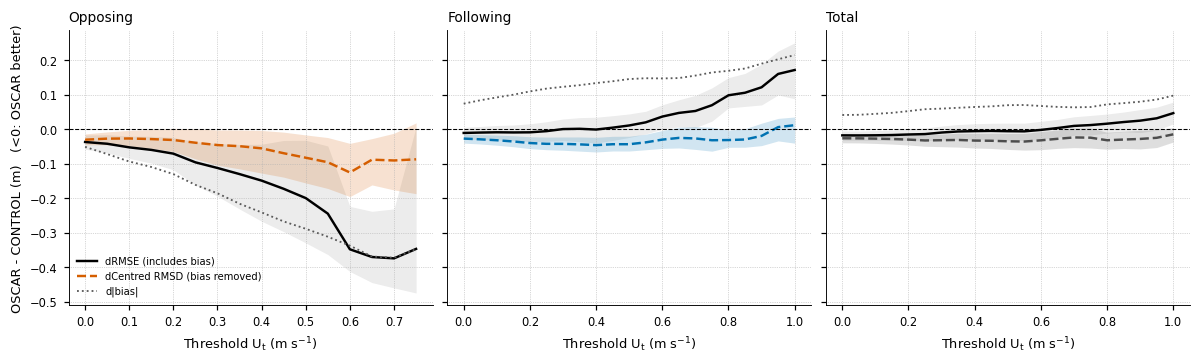

In [12]:
# ======================================================================
# CELL S1 - IS THE OPPOSING-CURRENT BENEFIT JUST A BIAS SHIFT?
# RMSE (uncentred) = sqrt(bias^2 + centred^2). If OSCAR only moved the mean bias,
# the centred RMSD would not change. Same passes, same bootstrap draws as Figure 4.
# ======================================================================
err_control = control - obs
err_oscar = oscar - obs


def calculate_bias_point(mask):
    """Bias, RMSE and centred RMSD for CONTROL and OSCAR + pass-bootstrap CIs of the changes."""
    n = int(mask.sum())
    nan = float('nan')
    empty = {'N': 0, 'passes': 0}
    for name in ['bias_control', 'bias_oscar', 'rmse_control', 'rmse_oscar',
                 'centred_control', 'centred_oscar',
                 'd_rmse', 'd_rmse_low', 'd_rmse_high',
                 'd_centred', 'd_centred_low', 'd_centred_high',
                 'd_abs_bias', 'd_abs_bias_low', 'd_abs_bias_high']:
        empty[name] = nan
    if n == 0:
        return empty

    ec, eo = err_control[mask], err_oscar[mask]
    bias_c, bias_o = ec.mean(), eo.mean()
    rmse_c, rmse_o = np.sqrt(np.mean(ec ** 2)), np.sqrt(np.mean(eo ** 2))
    cent_c, cent_o = np.sqrt(np.mean((ec - bias_c) ** 2)), np.sqrt(np.mean((eo - bias_o) ** 2))

    # Per-pass sums, then resample WHOLE passes (identical draws to Figure 4).
    def by_pass(values):
        return np.bincount(pass_codes[mask], weights=values, minlength=number_of_passes)

    cnt = np.bincount(pass_codes[mask], minlength=number_of_passes).astype(float)
    s_c, s_c2 = by_pass(ec), by_pass(ec ** 2)
    s_o, s_o2 = by_pass(eo), by_pass(eo ** 2)

    bn = cnt[bootstrap_pass_indices].sum(axis=1)
    ok = bn > 0
    bn = bn[ok]
    mc = s_c[bootstrap_pass_indices].sum(axis=1)[ok] / bn
    mc2 = s_c2[bootstrap_pass_indices].sum(axis=1)[ok] / bn
    mo = s_o[bootstrap_pass_indices].sum(axis=1)[ok] / bn
    mo2 = s_o2[bootstrap_pass_indices].sum(axis=1)[ok] / bn

    b_d_rmse = np.sqrt(mo2) - np.sqrt(mc2)
    b_d_cent = np.sqrt(np.maximum(mo2 - mo ** 2, 0)) - np.sqrt(np.maximum(mc2 - mc ** 2, 0))
    b_d_abs = np.abs(mo) - np.abs(mc)

    ci = lambda x: np.percentile(x, [2.5, 97.5])
    return {
        'N': n, 'passes': int(np.unique(pass_codes[mask]).size),
        'bias_control': bias_c, 'bias_oscar': bias_o,
        'rmse_control': rmse_c, 'rmse_oscar': rmse_o,
        'centred_control': cent_c, 'centred_oscar': cent_o,
        'd_rmse': rmse_o - rmse_c, 'd_rmse_low': ci(b_d_rmse)[0], 'd_rmse_high': ci(b_d_rmse)[1],
        'd_centred': cent_o - cent_c, 'd_centred_low': ci(b_d_cent)[0], 'd_centred_high': ci(b_d_cent)[1],
        'd_abs_bias': abs(bias_o) - abs(bias_c), 'd_abs_bias_low': ci(b_d_abs)[0], 'd_abs_bias_high': ci(b_d_abs)[1],
    }


bias_rows = []
for regime in ['opposing', 'following', 'total']:
    for threshold in THRESHOLDS:
        if regime == 'opposing':
            mask = u_parallel < -threshold
        elif regime == 'following':
            mask = u_parallel > threshold
        else:
            mask = np.ones(len(df_common), dtype=bool) if threshold == 0 else current_speed > threshold
        row = calculate_bias_point(mask)
        row['regime'] = regime
        row['threshold_ms'] = threshold
        row['shown'] = row['N'] >= MIN_N_CURVE and row['passes'] >= MIN_PASSES_CURVE
        bias_rows.append(row)

bias_data = pd.DataFrame(bias_rows)
bias_path = os.path.join(DATA_DIR, 'Supplement_S1_bias_vs_centred_rmsd.csv')
bias_data.to_csv(bias_path, index=False)
FILES_CREATED.append(bias_path)

# Consistency check: the d_rmse column must reproduce Figure 4(c) exactly.
check = bias_data.merge(threshold_data[['regime', 'threshold_ms', 'rmsd_change', 'rmsd_change_low', 'rmsd_change_high']],
                        on=['regime', 'threshold_ms'])
check = check[check['N'] > 0]
print('Check vs Figure 4(c): max |d_rmse - rmsd_change| =',
      f"{np.nanmax(np.abs(check['d_rmse'] - check['rmsd_change'])):.2e}",
      '| max CI-edge difference =',
      f"{np.nanmax(np.abs(check[['d_rmse_low','d_rmse_high']].to_numpy() - check[['rmsd_change_low','rmsd_change_high']].to_numpy())):.2e}",
      ' (both should be ~0)')

# ---- Supplementary Table S1: selected thresholds ----
selected = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
t_s1 = bias_data[bias_data['shown'] & bias_data['threshold_ms'].round(2).isin(selected)].copy()
tableS1 = pd.DataFrame({
    'Regime': t_s1['regime'],
    'U_t (m/s)': t_s1['threshold_ms'].map(lambda x: f'{x:.1f}'),
    'N': t_s1['N'].astype(int),
    'Passes': t_s1['passes'].astype(int),
    'Bias CONTROL (m)': t_s1['bias_control'].map(lambda x: f'{x:+.3f}'),
    'Bias OSCAR (m)': t_s1['bias_oscar'].map(lambda x: f'{x:+.3f}'),
    'dRMSE [95% CI] (m)': [format_ci(a, b, c, 3) for a, b, c in zip(t_s1['d_rmse'], t_s1['d_rmse_low'], t_s1['d_rmse_high'])],
    'dCentred RMSD [95% CI] (m)': [format_ci(a, b, c, 3) for a, b, c in zip(t_s1['d_centred'], t_s1['d_centred_low'], t_s1['d_centred_high'])],
})
save_table(tableS1, 'Table_S1_bias_vs_centred_rmsd.csv')
display(tableS1)

# ---- Plain-language read-out ----
print('\nPLAIN-LANGUAGE READ-OUT (negative = OSCAR better)')
for regime, ut in [('opposing', 0.2), ('opposing', 0.4), ('following', 0.8)]:
    sel = bias_data[(bias_data['regime'] == regime) & np.isclose(bias_data['threshold_ms'], ut)]
    if len(sel) == 0 or not bool(sel['shown'].iloc[0]):
        print(f'{regime.upper()} U_t={ut}: not enough data under the reporting rule.')
        continue
    r = sel.iloc[0]
    print(f"{regime.upper()} U_t={ut} (N={int(r['N'])}, passes={int(r['passes'])}): "
          f"bias {r['bias_control']:+.3f} -> {r['bias_oscar']:+.3f} m; "
          f"dRMSE {r['d_rmse']:+.3f} [{r['d_rmse_low']:+.3f}, {r['d_rmse_high']:+.3f}]; "
          f"dCentred {r['d_centred']:+.3f} [{r['d_centred_low']:+.3f}, {r['d_centred_high']:+.3f}]")
    if regime == 'opposing':
        if r['d_centred_high'] < 0:
            share = 100 * r['d_centred'] / r['d_rmse'] if r['d_rmse'] != 0 else float('nan')
            print(f"   -> NOT just a bias shift: the bias-removed error also falls (CI excludes zero); "
                  f"about {share:.0f}% of the RMSE change remains after removing bias.")
        else:
            print('   -> The bias-removed change is not clearly below zero: the benefit cannot be separated '
                  'from a shift in mean bias. Say so in the paper.')

# ---- Figure S1 ----
fig, axes = plt.subplots(1, 3, figsize=(10.8, 3.2), sharey=True, constrained_layout=True)
for ax, regime, colour in zip(axes, ['opposing', 'following', 'total'], [C_OPPOSING, C_FOLLOWING, C_TOTAL]):
    sub = bias_data[(bias_data['regime'] == regime) & bias_data['shown']]
    ax.plot(sub['threshold_ms'], sub['d_rmse'], color='k', linewidth=1.6, label='dRMSE (includes bias)')
    ax.fill_between(sub['threshold_ms'], sub['d_rmse_low'], sub['d_rmse_high'], color='0.5', alpha=0.15, linewidth=0)
    ax.plot(sub['threshold_ms'], sub['d_centred'], color=colour, linewidth=1.6, linestyle='--', label='dCentred RMSD (bias removed)')
    ax.fill_between(sub['threshold_ms'], sub['d_centred_low'], sub['d_centred_high'], color=colour, alpha=0.18, linewidth=0)
    ax.plot(sub['threshold_ms'], sub['d_abs_bias'], color='0.35', linewidth=1.2, linestyle=':', label='d|bias|')
    ax.axhline(0, color='k', linewidth=0.7, linestyle='--')
    ax.set_title(regime.capitalize(), loc='left')
    ax.set_xlabel(r'Threshold $U_t$ (m s$^{-1}$)')
    ax.grid(True, linestyle=':', linewidth=0.45)
axes[0].set_ylabel('OSCAR - CONTROL (m)   (<0: OSCAR better)')
axes[0].legend(frameon=False, fontsize=6.5, loc='lower left')
FIGS1_PATH = save_figure(fig, 'Figure_S1_bias_vs_centred_rmsd')
plt.show()


In [13]:
# ======================================================================
# CELL S2 - THRESHOLD CONSISTENCY (re-reads Figure 4c; nothing is recomputed)
# Question: does the sign of the RMSE change stay the same at every threshold?
# ======================================================================
rows = []
for regime in ['opposing', 'following', 'total']:
    sub = threshold_data[(threshold_data['regime'] == regime) & threshold_data['shown']]
    rows.append({
        'Regime': regime,
        'Thresholds shown': len(sub),
        'U_t range shown (m/s)': f"{sub['threshold_ms'].min():.2f} to {sub['threshold_ms'].max():.2f}",
        'OSCAR better (change < 0)': int((sub['rmsd_change'] < 0).sum()),
        'OSCAR worse (change > 0)': int((sub['rmsd_change'] > 0).sum()),
        'CI entirely < 0': int((sub['rmsd_change_high'] < 0).sum()),
        'CI entirely > 0': int((sub['rmsd_change_low'] > 0).sum()),
        'Smallest change (m)': round(float(sub['rmsd_change'].min()), 3),
        'Largest change (m)': round(float(sub['rmsd_change'].max()), 3),
    })
tableS2 = pd.DataFrame(rows)
save_table(tableS2, 'Table_S2_threshold_consistency.csv')
display(tableS2)

print('\nPLAIN-LANGUAGE READ-OUT')
for r in rows:
    n = r['Thresholds shown']
    print(f"{r['Regime'].upper()}: OSCAR better at {r['OSCAR better (change < 0)']} of {n} thresholds, "
          f"worse at {r['OSCAR worse (change > 0)']}; CI excludes zero on the better side at {r['CI entirely < 0']}, "
          f"on the worse side at {r['CI entirely > 0']}.")
print('Note: thresholds overlap (cumulative subsets), so these counts are NOT independent tests. '
      'Report them as a consistency check, not as a significance count.')


Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/tables/Table_S2_threshold_consistency.csv


,Regime,Thresholds shown,U_t range shown (m/s),OSCAR better (change < 0),OSCAR worse (change > 0),CI entirely < 0,CI entirely > 0,Smallest change (m),Largest change (m)
0,opposing,16,0.00 to 0.75,16,0,15,0,-0.374,-0.037
1,following,21,0.00 to 1.00,7,14,0,9,-0.010,0.172
2,total,21,0.00 to 1.00,13,8,4,1,-0.018,0.047



PLAIN-LANGUAGE READ-OUT
OPPOSING: OSCAR better at 16 of 16 thresholds, worse at 0; CI excludes zero on the better side at 15, on the worse side at 0.
FOLLOWING: OSCAR better at 7 of 21 thresholds, worse at 14; CI excludes zero on the better side at 0, on the worse side at 9.
TOTAL: OSCAR better at 13 of 21 thresholds, worse at 8; CI excludes zero on the better side at 4, on the worse side at 1.
Note: thresholds overlap (cumulative subsets), so these counts are NOT independent tests. Report them as a consistency check, not as a significance count.


Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/tables/Table_S3_binwidth_sensitivity.csv


,Bin width (m/s),Bins shown,Spearman rho (centre vs median dHs),Opposing bins with median dHs > 0,Following bins with median dHs < 0
0,0.05,33,-0.980,10 of 10,19 of 19
1,0.10,19,-0.996,7 of 7,10 of 10
2,0.20,10,-1.000,4 of 4,6 of 6


Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/figures/Figure_S2_binwidth_sensitivity.png


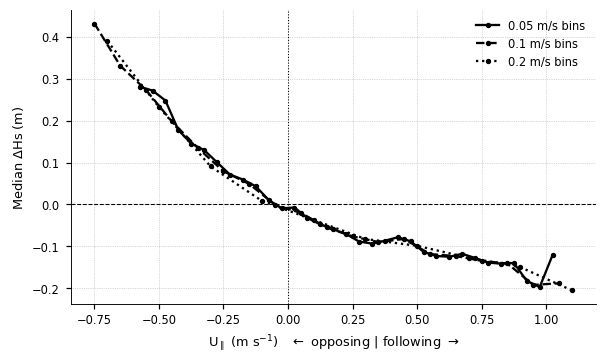

Read-out: if rho is strongly negative and opposing/following bins keep their signs at every width, the Figure 4(b) pattern does not depend on the bin width.


In [14]:
# ======================================================================
# CELL S3 - BIN-WIDTH SENSITIVITY OF FIGURE 4(b)
# ======================================================================
BIN_WIDTHS = [0.05, 0.10, 0.20]
binwidth_rows = []

for width in BIN_WIDTHS:
    edges = np.round(np.arange(BIN_EDGES[0], BIN_EDGES[-1] + 1e-9, width), 4)
    for lower, upper in zip(edges[:-1], edges[1:]):
        mask = (u_parallel > lower) & (u_parallel <= upper)
        n = int(mask.sum())
        if n == 0:
            continue
        binwidth_rows.append({
            'bin_width_ms': width, 'bin_centre_ms': (lower + upper) / 2, 'N': n,
            'passes': int(np.unique(pass_codes[mask]).size),
            'median_dhs_m': float(np.median(df_common['dhs'].to_numpy()[mask])),
            'shown': n >= MIN_N_BIN
        })

binwidth_data = pd.DataFrame(binwidth_rows)
bw_path = os.path.join(DATA_DIR, 'Supplement_S3_binned_response_by_width.csv')
binwidth_data.to_csv(bw_path, index=False)
FILES_CREATED.append(bw_path)

summary_rows = []
for width in BIN_WIDTHS:
    sub = binwidth_data[(binwidth_data['bin_width_ms'] == width) & binwidth_data['shown']]
    rho = stats.spearmanr(sub['bin_centre_ms'], sub['median_dhs_m'])[0] if len(sub) > 2 else np.nan
    opp = sub[sub['bin_centre_ms'] <= -0.1]
    fol = sub[sub['bin_centre_ms'] >= 0.1]
    summary_rows.append({
        'Bin width (m/s)': width,
        'Bins shown': len(sub),
        'Spearman rho (centre vs median dHs)': round(float(rho), 3),
        'Opposing bins with median dHs > 0': f'{int((opp["median_dhs_m"] > 0).sum())} of {len(opp)}',
        'Following bins with median dHs < 0': f'{int((fol["median_dhs_m"] < 0).sum())} of {len(fol)}',
    })
tableS3 = pd.DataFrame(summary_rows)
save_table(tableS3, 'Table_S3_binwidth_sensitivity.csv')
display(tableS3)

fig, ax = plt.subplots(figsize=(5.4, 3.2), constrained_layout=True)
for width, style in zip(BIN_WIDTHS, ['-', '--', ':']):
    sub = binwidth_data[(binwidth_data['bin_width_ms'] == width) & binwidth_data['shown']]
    ax.plot(sub['bin_centre_ms'], sub['median_dhs_m'], style, marker='o', markersize=2.5, color='k', label=f'{width} m/s bins')
ax.axhline(0, color='k', linewidth=0.7, linestyle='--')
ax.axvline(0, color='k', linewidth=0.7, linestyle=':')
ax.set_xlabel(r'$U_\parallel$ (m s$^{-1}$)   $\leftarrow$ opposing | following $\rightarrow$')
ax.set_ylabel(r'Median $\Delta$Hs (m)')
ax.legend(frameon=False)
ax.grid(True, linestyle=':', linewidth=0.45)
FIGS2_PATH = save_figure(fig, 'Figure_S2_binwidth_sensitivity')
plt.show()
print('Read-out: if rho is strongly negative and opposing/following bins keep their signs at every width, '
      'the Figure 4(b) pattern does not depend on the bin width.')


In [15]:
# ======================================================================
# CELL S4 - LEAVE-ONE-MISSION-OUT (does any single mission drive the result?)
# Re-uses calculate_threshold_point() from Figure 4, so the method is identical.
# ======================================================================
mission_array = df_common['satellite'].astype(str).to_numpy()
missions_used = sorted(set(mission_array))

cases = [('opposing', 0.2), ('opposing', 0.4), ('following', 0.8), ('total', 0.0)]
lomo_rows = []

for regime, ut in cases:
    if regime == 'opposing':
        base_mask = u_parallel < -ut
    elif regime == 'following':
        base_mask = u_parallel > ut
    else:
        base_mask = np.ones(len(df_common), dtype=bool) if ut == 0 else current_speed > ut

    for dropped in ['(none dropped)'] + missions_used:
        mask = base_mask if dropped == '(none dropped)' else base_mask & (mission_array != dropped)
        r = calculate_threshold_point(mask)
        lomo_rows.append({
            'Regime': regime, 'U_t (m/s)': ut, 'Mission dropped': dropped,
            'N': int(r['N']), 'Passes': int(r['passes']),
            'dRMSE (m)': r['rmsd_change'], 'CI low': r['rmsd_change_low'], 'CI high': r['rmsd_change_high'],
            'Enough data': bool(r['N'] >= MIN_N_CURVE and r['passes'] >= MIN_PASSES_CURVE)
        })

lomo = pd.DataFrame(lomo_rows)
save_table(lomo, 'Table_S4_leave_one_mission_out.csv')
display(lomo.round(3))

print('\nPLAIN-LANGUAGE READ-OUT')
for regime, ut in cases:
    sub = lomo[(lomo['Regime'] == regime) & (lomo['U_t (m/s)'] == ut) & (lomo['Mission dropped'] != '(none dropped)') & lomo['Enough data']]
    full = lomo[(lomo['Regime'] == regime) & (lomo['U_t (m/s)'] == ut) & (lomo['Mission dropped'] == '(none dropped)')].iloc[0]
    if len(sub) == 0:
        print(f'{regime.upper()} U_t={ut}: not enough data after dropping missions.')
        continue
    same_sign = int((np.sign(sub['dRMSE (m)']) == np.sign(full['dRMSE (m)'])).sum())
    if full['dRMSE (m)'] < 0:
        excl = int((sub['CI high'] < 0).sum())
    else:
        excl = int((sub['CI low'] > 0).sum())
    print(f"{regime.upper()} U_t={ut}: full-sample dRMSE {full['dRMSE (m)']:+.3f} m; across the {len(sub)} leave-one-out runs it ranges "
          f"{sub['dRMSE (m)'].min():+.3f} to {sub['dRMSE (m)'].max():+.3f} m; same sign in {same_sign} of {len(sub)}; "
          f"CI still excludes zero in {excl} of {len(sub)}.")


Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/tables/Table_S4_leave_one_mission_out.csv


,Regime,U_t (m/s),Mission dropped,N,Passes,dRMSE (m),CI low,CI high,Enough data
0,opposing,0.2,(none dropped),1086,40,-0.070,-0.117,-0.023,True
1,opposing,0.2,CryoSat-2,890,34,-0.085,-0.138,-0.026,True
2,opposing,0.2,HY-2B,1033,38,-0.071,-0.120,-0.023,True
3,opposing,0.2,HY-2C,926,35,-0.075,-0.123,-0.027,True
4,opposing,0.2,Jason-3,1011,38,-0.066,-0.116,-0.017,True
5,opposing,0.2,SARAL/AltiKa,980,37,-0.063,-0.110,-0.017,True
6,opposing,0.2,SWOT-nadir,972,35,-0.076,-0.128,-0.024,True
7,opposing,0.2,Sentinel-3A,991,34,-0.071,-0.120,-0.022,True
8,opposing,0.2,Sentinel-3B,936,35,-0.055,-0.101,-0.009,True
9,opposing,0.2,Sentinel-6A,949,34,-0.074,-0.122,-0.025,True



PLAIN-LANGUAGE READ-OUT
OPPOSING U_t=0.2: full-sample dRMSE -0.070 m; across the 9 leave-one-out runs it ranges -0.085 to -0.055 m; same sign in 9 of 9; CI still excludes zero in 9 of 9.
OPPOSING U_t=0.4: full-sample dRMSE -0.149 m; across the 9 leave-one-out runs it ranges -0.189 to -0.123 m; same sign in 9 of 9; CI still excludes zero in 9 of 9.
FOLLOWING U_t=0.8: full-sample dRMSE +0.099 m; across the 9 leave-one-out runs it ranges +0.080 to +0.128 m; same sign in 9 of 9; CI still excludes zero in 9 of 9.
TOTAL U_t=0.0: full-sample dRMSE -0.017 m; across the 9 leave-one-out runs it ranges -0.020 to -0.012 m; same sign in 9 of 9; CI still excludes zero in 9 of 9.



## Final step - build the Word results file

This cell creates a **main-paper-only** Word compilation. It includes the four figures and three tables above (Tables 1, 2 and 4), and intentionally leaves out the supplementary and audit material. CELL 12B then saves PDF copies of the Word files.

You normally do not need to edit this cell unless you want to change Word formatting.


In [16]:

# ======================================================================
# CELL 12 - BUILD MAIN-PAPER WORD COMPILATION
# ======================================================================

from docx import Document
from docx.shared import Pt, Cm, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.table import WD_TABLE_ALIGNMENT


def add_dataframe_table(document, dataframe, font_size=8):
    """Add a simple dataframe as a Word table."""
    table = document.add_table(rows=1, cols=len(dataframe.columns))
    table.alignment = WD_TABLE_ALIGNMENT.CENTER
    table.style = 'Table Grid'

    # Header row.
    for column_number, column_name in enumerate(dataframe.columns):
        cell = table.rows[0].cells[column_number]
        cell.text = str(column_name)
        for run in cell.paragraphs[0].runs:
            run.bold = True
            run.font.size = Pt(font_size)

    # Data rows.
    for _, row in dataframe.iterrows():
        cells = table.add_row().cells
        for column_number, column_name in enumerate(dataframe.columns):
            value = row[column_name]

            if isinstance(value, (float, np.floating)):
                text = f'{value:.3f}'
            elif isinstance(value, (int, np.integer)):
                text = f'{int(value):,}'
            else:
                text = str(value)

            cells[column_number].text = text
            for run in cells[column_number].paragraphs[0].runs:
                run.font.size = Pt(font_size)

    return table


def add_figure(document, image_path, caption_text, width_cm):
    """Insert one figure and its caption."""
    paragraph = document.add_paragraph()
    paragraph.alignment = WD_ALIGN_PARAGRAPH.CENTER
    paragraph.add_run().add_picture(image_path, width=Cm(width_cm))

    caption = document.add_paragraph(caption_text)
    caption.alignment = WD_ALIGN_PARAGRAPH.LEFT
    caption.paragraph_format.space_after = Pt(8)


DOCX_TEXT_COLOUR = RGBColor(0, 0, 0)   # <---------------- change this to set the colour of all titles and headings (black)


def make_text_black(document):
    """Make the Word title and heading styles black and remove the coloured line under the title."""
    for style_name in ['Title', 'Heading 1', 'Heading 2', 'Heading 3']:
        try:
            style = document.styles[style_name]
        except KeyError:
            continue
        style.font.color.rgb = DOCX_TEXT_COLOUR
        # The default Title style draws a blue border line below the text; remove it.
        paragraph_properties = style.element.pPr
        if paragraph_properties is not None:
            for border in paragraph_properties.findall(
                    '{http://schemas.openxmlformats.org/wordprocessingml/2006/main}pBdr'):
                paragraph_properties.remove(border)


# ----------------------------------------------------------------------
# Start the document.
# ----------------------------------------------------------------------
doc = Document()
section = doc.sections[0]
section.left_margin = Cm(2.0)
section.right_margin = Cm(2.0)
section.top_margin = Cm(2.0)
section.bottom_margin = Cm(2.0)

doc.styles['Normal'].font.name = 'Calibri'
doc.styles['Normal'].font.size = Pt(10)
make_text_black(doc)

doc.add_heading('Cyclone Remal (2024): effect of prescribed OSCAR surface currents on WAVEWATCH III waves', level=0)

intro = doc.add_paragraph()
intro.add_run(
    f'Main-paper results compilation. Analysis window {T_START} to {T_END} UTC (inclusive). '
    f'Common sample: {len(df_common):,} altimeter 1-Hz observations from '
    f'{df_common["altimeter_pass_id"].nunique()} passes.'
).italic = True

doc.add_paragraph(
    'The analysis window ends at 28 May 00 UTC to keep the evaluation focused on the Remal event '
    'and avoid mixing the targeted storm-period comparison with the later post-storm wave field.'
)

doc.add_paragraph(
    'Differences between WW3 OSCAR and WW3 CONTROL are interpreted as the net response to prescribed '
    'surface-current forcing in this configuration (RWND active), not a pure refraction effect. '
    'ERA5 is a reanalysis benchmark, not independent, because it shares ERA5 winds and boundary spectra '
    'with the WW3 runs. Figure 4 is Hisaki-inspired, not a replication.'
)

# ----------------------------------------------------------------------
# Table 1
# ----------------------------------------------------------------------
doc.add_heading('Table 1. Model configuration and datasets', level=1)
add_dataframe_table(doc, table1, font_size=8)

# ----------------------------------------------------------------------
# Figure 1
# ----------------------------------------------------------------------
doc.add_heading('Figure 1. Study area', level=1)
add_figure(
    doc, FIG1_PATH,
    f'Figure 1. Study area. Dashed box: WAVEWATCH III domain. Solid line: hourly Cyclone Remal track (IMD), '
    f'24 May 00 UTC to 28 May 00 UTC 2024. '
    f'Small dots show altimeter 1-Hz sampling of the common comparison sample (N = {len(df_common):,}), coloured by mission. '
    f'Grey: land ({"Natural Earth coastlines" if HAVE_CARTOPY else "WW3 grid land mask"}).',
    width_cm=13.5   # <---------------- change this to customise the Figure 1 width in the Word file
)

# ----------------------------------------------------------------------
# Figure 2 + Table 2
# ----------------------------------------------------------------------
doc.add_heading('Figure 2. Hs validation', level=1)
add_figure(
    doc, FIG2_PATH,
    'Figure 2. Significant wave height against satellite altimeters on the common sample: '
    '(a) ERA5 reanalysis benchmark, (b) WW3 CONTROL, and (c) WW3 OSCAR. '
    'Colours show the percentage of points per 0.1 m cell; the line is 1:1. Bias = model - observation.',
    width_cm=17.0
)

doc.add_heading('Table 2. Common-sample validation', level=1)
add_dataframe_table(doc, table2, font_size=8)

# ----------------------------------------------------------------------
# Figure 3
# ----------------------------------------------------------------------
doc.add_heading('Figure 3. Direct WW3 response', level=1)
add_figure(
    doc, FIG3_PATH,
    'Figure 3. Net response of the WW3 wave field to prescribed OSCAR surface-current forcing, '
    '24 May 00 UTC to 28 May 00 UTC 2024. (a) Time-mean Delta Hs = Hs(OSCAR) - Hs(CONTROL) with the IMD track. '
    '(b) Area-weighted domain-mean absolute Delta Hs per hour. RWND was active, so the difference includes '
    'any current-relative-wind effect.',
    width_cm=17.0
)

# ----------------------------------------------------------------------
# Figure 4
# ----------------------------------------------------------------------
doc.add_heading('Figure 4. Current-direction dependence', level=1)
add_figure(
    doc, FIG4_PATH,
    'Figure 4. Hisaki-inspired analysis of current dependence. U_parallel is the OSCAR current component '
    'along the WW3 CONTROL mean wave-propagation direction (negative: opposing; positive: following). '
    '(a) Ratio of mean altimeter Hs to mean ERA5 Hs for cumulative thresholds. '
    '(b) Delta Hs = Hs(OSCAR) - Hs(CONTROL) in 0.1 m/s U_parallel bins; line = median and band = IQR. '
    '(c) RMSE(OSCAR) - RMSE(CONTROL), where values below zero mean OSCAR is closer to the altimeter. '
    'Confidence bands in (a) and (c) resample altimeter passes.',
    width_cm=17.0
)

# ----------------------------------------------------------------------
# Table 4 (pass-level robustness)
# ----------------------------------------------------------------------
doc.add_heading('Table 4. Pass-level robustness', level=1)
add_dataframe_table(doc, table3, font_size=8)

doc.add_paragraph(
    'Delta MAE_pass = MAE_OSCAR - MAE_CONTROL. Negative values mean OSCAR is closer to the altimeter. '
    'Passes, rather than individual 1-Hz points, are the bootstrap units.'
)

DOCX_PATH = os.path.join(OUT_DIR, DOCX_NAME)
doc.save(DOCX_PATH)
FILES_CREATED.append(DOCX_PATH)
print('Saved:', DOCX_PATH)


Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/Remal_WW3_main_paper_results.docx


## Supplementary Word file

Collects Tables S1-S4 and Figures S1-S2 in one Word file for the paper's supplement. Needs the main Word cell above to have run first.

In [17]:
# ======================================================================
# CELL S5 - SUPPLEMENTARY WORD FILE (Tables S1-S4, Figures S1-S2)
# Run AFTER the main Word compilation cell (it re-uses its helper functions).
# ======================================================================
sdoc = Document()
sec = sdoc.sections[0]
sec.left_margin = sec.right_margin = sec.top_margin = sec.bottom_margin = Cm(2.0)
sdoc.styles['Normal'].font.name = 'Calibri'
sdoc.styles['Normal'].font.size = Pt(10)
make_text_black(sdoc)

sdoc.add_heading('Supplementary material - robustness checks', level=0)
sdoc.add_paragraph(
    'All quantities use the same common sample, the same passes and the same pass-bootstrap draws as the main analysis. '
    'dRMSE and dCentred RMSD are OSCAR minus CONTROL (negative: OSCAR closer to the altimeter). '
    'Thresholds are cumulative and overlapping, so intervals are pointwise.'
)


def as_text_table(frame):
    out = frame.copy()
    for column in out.columns:
        out[column] = out[column].map(lambda v: 'n/a' if (isinstance(v, float) and not np.isfinite(v)) else (f'{v:.3f}' if isinstance(v, (float, np.floating)) else str(v)))
    return out


sdoc.add_heading('Table S1. Bias versus bias-removed error by regime', level=1)
add_dataframe_table(sdoc, as_text_table(tableS1), font_size=7)
add_figure(sdoc, FIGS1_PATH, 'Figure S1. OSCAR minus CONTROL change in RMSE (black), centred RMSD with the mean bias removed (dashed, coloured) '
           'and in absolute bias (dotted), against threshold. Bands: 95% whole-pass bootstrap intervals.', width_cm=17.0)

sdoc.add_heading('Table S2. Consistency of the RMSE change across thresholds', level=1)
add_dataframe_table(sdoc, as_text_table(tableS2), font_size=7)

sdoc.add_heading('Table S3. Bin-width sensitivity of the binned response', level=1)
add_dataframe_table(sdoc, as_text_table(tableS3), font_size=7)
add_figure(sdoc, FIGS2_PATH, 'Figure S2. Median OSCAR minus CONTROL Hs against the along-wave current component for three bin widths.', width_cm=11.0)

sdoc.add_heading('Table S4. Leave-one-mission-out', level=1)
add_dataframe_table(sdoc, as_text_table(lomo), font_size=6.5)

SUPP_DOCX_PATH = os.path.join(OUT_DIR, 'Remal_WW3_supplementary_robustness.docx')
sdoc.save(SUPP_DOCX_PATH)
FILES_CREATED.append(SUPP_DOCX_PATH)
print('Saved:', SUPP_DOCX_PATH)


Saved: /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/Remal_WW3_supplementary_robustness.docx


## PDF copies of the Word files

This cell saves a PDF next to each Word file (`Remal_WW3_main_paper_results.pdf` and `Remal_WW3_supplementary_robustness.pdf`), ready to upload or share.

- If **LibreOffice** is installed, it converts each Word file exactly, tables included. On Ubuntu you can install it with `sudo apt install libreoffice`. Close any open LibreOffice window first, because an open window can block the conversion.
- If LibreOffice is not found, the cell still makes a PDF: it places every saved figure on its own page with its title. Tables stay in the Word and CSV files.

Set `MAKE_PDF = False` in CELL 1 to skip this step.

In [18]:
# ======================================================================
# CELL 12B - PDF COPIES OF THE WORD FILES (for uploading / sharing)
# Drawing/export only: nothing in this cell changes any number.
# Run AFTER CELL 12 and CELL S5 (it needs the two Word files).
# ======================================================================

import shutil
import subprocess
from matplotlib.backends.backend_pdf import PdfPages

PDF_FALLBACK_PAGE_SIZE = (8.27, 11.69)   # <---------------- change this to set the fallback PDF page size in inches (A4 portrait)


def word_to_pdf(docx_path):
    """Convert one Word file to PDF with LibreOffice. Returns the PDF path, or None if it fails."""
    soffice = shutil.which('soffice') or shutil.which('libreoffice')
    if soffice is None:
        return None
    try:
        subprocess.run(
            [soffice, '--headless', '--convert-to', 'pdf', '--outdir', os.path.dirname(docx_path), docx_path],
            stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL, timeout=300, check=False
        )
    except Exception as error:
        print('LibreOffice conversion failed:', error)
        return None
    pdf_path = os.path.splitext(docx_path)[0] + '.pdf'
    return pdf_path if os.path.exists(pdf_path) else None


def figures_to_pdf(pdf_path, title, figures):
    """Fallback: one page per saved figure PNG, with a title. Needs only matplotlib."""
    with PdfPages(pdf_path) as pdf:
        for figure_title, image_path in figures:
            if not os.path.exists(image_path):
                print('  skipped (not found):', image_path)
                continue
            image = plt.imread(image_path)
            page = plt.figure(figsize=PDF_FALLBACK_PAGE_SIZE)
            page.text(0.5, 0.96, title, ha='center', va='top', fontsize=9, color='k')
            page.text(0.07, 0.92, figure_title, ha='left', va='top', fontsize=12, fontweight='bold')
            ax = page.add_axes([0.07, 0.08, 0.86, 0.80])
            ax.imshow(image)
            ax.axis('off')
            pdf.savefig(page)
            plt.close(page)
    return pdf_path


if MAKE_PDF:
    jobs = [
        (DOCX_PATH, 'Cyclone Remal (2024): WAVEWATCH III main-paper results', [
            ('Figure 1. Study area', FIG1_PATH),
            ('Figure 2. Hs validation', FIG2_PATH),
            ('Figure 3. Direct WW3 response', FIG3_PATH),
            ('Figure 4. Current-direction dependence', FIG4_PATH),
        ]),
        (SUPP_DOCX_PATH, 'Cyclone Remal (2024): WAVEWATCH III supplementary robustness checks', [
            ('Figure S1. Bias versus bias-removed error', FIGS1_PATH),
            ('Figure S2. Bin-width sensitivity', FIGS2_PATH),
        ]),
    ]

    for docx_path, title, figures in jobs:
        pdf_path = word_to_pdf(docx_path)
        if pdf_path is not None:
            print('Saved (LibreOffice copy of the Word file):', pdf_path)
        else:
            pdf_path = figures_to_pdf(os.path.splitext(docx_path)[0] + '.pdf', title, figures)
            print('Saved (figures-only PDF; LibreOffice not available):', pdf_path)
        FILES_CREATED.append(pdf_path)
else:
    print('MAKE_PDF is False: no PDF copies were made.')

Saved (LibreOffice copy of the Word file): /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/Remal_WW3_main_paper_results.pdf
Saved (LibreOffice copy of the Word file): /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/Remal_WW3_supplementary_robustness.pdf


## Final checklist

In [19]:

# ======================================================================
# CELL 13 - CHECK WHAT WAS CREATED
# ======================================================================

checklist_path = os.path.join(OUT_DIR, 'created_files_checklist.txt')

# Remove duplicates while keeping the original order.
unique_files = list(dict.fromkeys(FILES_CREATED))

with open(checklist_path, 'w', encoding='utf-8') as file:
    file.write('Files created by the final-paper notebook\n')
    for path in unique_files:
        status = 'OK' if os.path.exists(path) else 'MISSING'
        file.write(f'[{status}] {path}\n')

print('FINAL-PAPER OUTPUT CHECKLIST')
for path in unique_files:
    status = 'OK' if os.path.exists(path) else 'MISSING'
    print(f'[{status}] {path}')

print('[OK]', checklist_path)


FINAL-PAPER OUTPUT CHECKLIST
[OK] /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/tables/Table_1_model_configuration.csv
[OK] /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/figures/Figure_1_study_area.png
[OK] /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/figures/Figure_1_study_area.pdf
[OK] /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/tables/Table_2_validation_statistics.csv
[OK] /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/figures/Figure_2_Hs_validation.png
[OK] /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/figures/Figure_2_Hs_validation.pdf
[OK] /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/figure_data/Figure_3_time_series.csv
[OK] /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/figures/Figure_3_WW3_current_response.png
[OK] /home/ushmo/Desktop/remal_wavewatch_portfolio/final_paper_outputs/figures/Figure_3_WW3_current_response.p